# Lab 5: "Shout STOP!" Build the Brain of a Voice Emergency Stop

**Name:** Tanmay Gautam &nbsp;|&nbsp; **Register No.:** 2548559 &nbsp;|&nbsp; **Course:** TinyML

---

## Lab question

**Aim**

To train a keyword spotting model in Google Colab that detects the word "stop", using the Google Speech Commands dataset, MFCC features and a DS-CNN.

**Objectives**

1. Prepare a dataset with the classes stop, \_unknown\_ and \_silence\_.
2. Preprocess audio and extract spectrogram and MFCC features.
3. Train and evaluate a DS-CNN keyword spotting model.
4. Convert the model to int8 TensorFlow Lite for a microcontroller.

**The problem**

SafeLine Packaging Pvt. Ltd. runs a fast conveyor belt in Bengaluru. Last month a worker's glove got caught in the rollers. The red emergency button was 4 metres away, and it took 6 seconds to reach it. Nobody was badly hurt, but the safety officer was clear: "Next time, the worker must be able to just shout STOP and the belt must halt."

The company cannot send audio to the cloud. The factory Wi-Fi drops often, a cloud delay could cost a finger, and the workers do not want their talk recorded. The solution must run on a tiny microcontroller fixed on the machine, with less than 100 KB of memory for the model.

You are the TinyML engineer. Before buying any hardware, the manager wants proof in Google Colab that a small model can tell "stop" apart from every other word and from machine noise. You will use the Google Speech Commands dataset (Mini Speech Commands): 8 words, about 1,000 one-second clips per word, 16 kHz, many speakers.

Download link: http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip

**Your tasks**

1. **Collect the evidence (dataset preparation).** Workers talk all day, saying "go", "no", "left", "yes". The belt must react only to "stop". Build 3 classes from the dataset:
   - stop: all clips from the stop folder
   - \_unknown\_: random clips from the other 7 words, the same number as stop
   - \_silence\_: 1 s background-noise clips, the same number as stop

   Split the data 80/10/10 by speaker, so your test uses voices the model has never heard. New workers join every month.
2. **Make the audio ready (preprocessing).** Load every clip as 16 kHz mono, exactly 1 second. Cut it into frames with a 30 ms window and 20 ms hop.
3. **Show what the machine "hears" (features).** Plot the waveform, spectrogram and MFCC (49 × 10) for a "stop" clip and a "go" clip. Explain to the manager, in 3 lines, why the MFCC pictures look different.
4. **Design the brain (KWS architecture).** Build a small DS-CNN with MFCC input and a 3-class output. Report its parameters. Will it fit in under 100 KB?
5. **Teach it (training workflow).** Train with augmentation: time shift for workers who speak early or late, and background noise for a loud factory. Plot the accuracy and loss curves.
6. **Safety check (evaluation).** Report test accuracy and the confusion matrix. The safety officer wants two numbers:
   - Misses: how many "stop" words did the model not catch? (Dangerous: the belt keeps running.)
   - False alarms: how many other words did it wrongly call "stop"? (Costly: the line halts for no reason.)
7. **Make it fit the chip (deployment preparation).** Convert to int8 TFLite. Compare float and int8 size and accuracy, and export kws_int8.tflite and kws_config.json for Lab 6.

**Expected results**

- A balanced dataset table across train, validation and test
- MFCC plots where "stop" shows a clear pattern different from "go"
- Test accuracy of about 85 to 95% on unseen speakers
- Miss and false-alarm counts reported from the confusion matrix
- int8 model of about 45 to 50 KB (it fits the 100 KB limit), with less than 1% accuracy loss

**Rubric (10 marks):** Dataset preparation and features (3) | Model training and safety evaluation (3) | Quantization, analysis and viva (4)

---

### Abbreviations used in this notebook

| Short form | Full form |
|---|---|
| KWS | Keyword Spotting |
| MFCC | Mel-Frequency Cepstral Coefficients |
| DS-CNN | Depthwise Separable Convolutional Neural Network |
| TFLite | TensorFlow Lite |
| STFT | Short-Time Fourier Transform |
| FFT | Fast Fourier Transform |
| DCT | Discrete Cosine Transform |
| SNR | Signal-to-Noise Ratio (in decibels, dB) |
| RMS | Root Mean Square (a measure of loudness) |
| BN | Batch Normalization |
| ReLU | Rectified Linear Unit |
| int8 | 8-bit signed integer |
| RAM | Random Access Memory |
| KB | Kilobyte (1,024 bytes in this notebook) |

### Running this notebook locally on a Mac

This notebook was written for Google Colab in the lab sheet, but it runs locally. It reads the dataset from `/Users/Tanmay/Downloads/mini_speech_commands.zip`, extracts it into `~/Downloads/Lab5_KWS/data`, and saves every plot and model file into `~/Downloads/Lab5_KWS/outputs`. Only `tensorflow`, `numpy`, `pandas` and `matplotlib` are needed for sections 0 to 8. The live microphone demo in section 9 also needs `sounddevice` and `scipy`, and the conveyor belt video demo in 9.4 needs `opencv-python`. No GPU is needed: the full run takes a few minutes on a laptop CPU.

## 0. Setup and configuration

All settings that the lab fixes (16 kHz, 1 s clips, 30 ms window, 20 ms hop, 49 × 10 MFCC, 3 classes) are defined once here, so the same values can be written into `kws_config.json` for Lab 6.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import io
import json
import time
import contextlib
import wave
import random
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

ZIP_PATH = Path("/Users/Tanmay/Downloads/mini_speech_commands.zip")
WORK_DIR = ZIP_PATH.parent / "Lab5_KWS"
DATA_DIR = WORK_DIR / "data"
OUT_DIR = WORK_DIR / "outputs"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_RATE = 16000
CLIP_SAMPLES = SAMPLE_RATE * 1
WINDOW_MS = 30
HOP_MS = 20
FRAME_LENGTH = SAMPLE_RATE * WINDOW_MS // 1000
FRAME_STEP = SAMPLE_RATE * HOP_MS // 1000
FFT_LENGTH = 512
NUM_MEL_BINS = 40
MEL_LOW_HZ = 20.0
MEL_HIGH_HZ = 7600.0
LOG_OFFSET = 1e-6
NUM_MFCC = 10
NUM_FRAMES = 1 + (CLIP_SAMPLES - FRAME_LENGTH) // FRAME_STEP

KEYWORD = "stop"
LABELS = ["stop", "_unknown_", "_silence_"]
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
STOP_ID = LABEL_TO_ID["stop"]
SPLITS = ["train", "validation", "test"]

BATCH_SIZE = 64
EPOCHS = 60
MAX_SHIFT_MS = 100
MAX_SHIFT = SAMPLE_RATE * MAX_SHIFT_MS // 1000
NOISE_PROB = 0.8
SNR_RANGE_DB = (0.0, 20.0)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 10})

print("TensorFlow version :", tf.__version__)
print("Dataset zip        :", ZIP_PATH, "| found:", ZIP_PATH.exists())
print("Outputs folder     :", OUT_DIR)
print(f"Frame length = {FRAME_LENGTH} samples ({WINDOW_MS} ms), hop = {FRAME_STEP} samples ({HOP_MS} ms)")
print(f"Frames per 1 s clip = 1 + ({CLIP_SAMPLES} - {FRAME_LENGTH}) // {FRAME_STEP} = {NUM_FRAMES}")
print(f"MFCC feature shape  = {NUM_FRAMES} x {NUM_MFCC}")

TensorFlow version : 2.22.0-rc0
Dataset zip        : /Users/Tanmay/Downloads/mini_speech_commands.zip | found: True
Outputs folder     : /Users/Tanmay/Downloads/Lab5_KWS/outputs
Frame length = 480 samples (30 ms), hop = 320 samples (20 ms)
Frames per 1 s clip = 1 + (16000 - 480) // 320 = 49
MFCC feature shape  = 49 x 10


## 1. Collect the evidence (dataset preparation)

### 1.1 Extract the dataset

The zip file also contains a `__MACOSX` folder with hidden macOS metadata files. Those are skipped so that only the real WAV clips are extracted.

In [2]:
SPEECH_DIR = DATA_DIR / "mini_speech_commands"

if not SPEECH_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH) as zf:
        members = [m for m in zf.namelist() if not m.startswith("__MACOSX")]
        zf.extractall(DATA_DIR, members=members)
    print("Extracted to", SPEECH_DIR)
else:
    print("Already extracted at", SPEECH_DIR)

WORDS = sorted(d.name for d in SPEECH_DIR.iterdir() if d.is_dir() and not d.name.startswith("_"))
word_files = {w: sorted((SPEECH_DIR / w).glob("*.wav")) for w in WORDS}

print("Words found:", WORDS)
pd.DataFrame({"word": WORDS, "clips": [len(word_files[w]) for w in WORDS]}).set_index("word").T

Already extracted at /Users/Tanmay/Downloads/Lab5_KWS/data/mini_speech_commands
Words found: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']


word,down,go,left,no,right,stop,up,yes
clips,1000,1000,1000,1000,1000,1000,1000,1000


### 1.2 Check the audio format

Every clip should already be 16 kHz, mono, 16-bit. Some clips are shorter than 1 second, so they will be zero-padded later. This cell reads only the WAV headers, so it is fast.

In [3]:
def wav_info(path):
    with wave.open(str(path), "rb") as w:
        return w.getframerate(), w.getnchannels(), w.getsampwidth() * 8, w.getnframes()

info = pd.DataFrame(
    [(w, *wav_info(p)) for w in WORDS for p in word_files[w]],
    columns=["word", "sample_rate", "channels", "bits", "samples"],
)
print("Sample rates   :", sorted(info.sample_rate.unique()))
print("Channels       :", sorted(info.channels.unique()))
print("Bit depth      :", sorted(info.bits.unique()))
print(f"Clip length    : min {info.samples.min()} | max {info.samples.max()} samples")
print(f"Clips shorter than 1 s (will be zero-padded): {(info.samples < CLIP_SAMPLES).sum()} of {len(info)}")
assert (info.sample_rate == SAMPLE_RATE).all(), "A clip is not 16 kHz"
assert (info.channels == 1).all(), "A clip is not mono"

Sample rates   : [np.int64(16000)]
Channels       : [np.int64(1)]
Bit depth      : [np.int64(16)]
Clip length    : min 6827 | max 16000 samples
Clips shorter than 1 s (will be zero-padded): 822 of 8000


### 1.3 Speaker-wise 80 / 10 / 10 split

In Speech Commands the file name starts with a speaker ID, for example `0ab3b47d_nohash_0.wav` was recorded by speaker `0ab3b47d`. The speakers (not the clips) are shuffled and split 80 / 10 / 10. Every clip then goes to the split of its speaker. This means the test set only contains voices the model has never heard, which is what happens when new workers join the factory.

In [4]:
def speaker_of(path):
    return Path(path).name.split("_nohash_")[0]

all_speakers = sorted({speaker_of(p) for w in WORDS for p in word_files[w]})
rng = np.random.default_rng(SEED)
shuffled_speakers = rng.permutation(all_speakers)
n_spk = len(shuffled_speakers)
n_train_spk = int(round(0.8 * n_spk))
n_val_spk = int(round(0.1 * n_spk))

speaker_split = {}
for i, spk in enumerate(shuffled_speakers):
    if i < n_train_spk:
        speaker_split[spk] = "train"
    elif i < n_train_spk + n_val_spk:
        speaker_split[spk] = "validation"
    else:
        speaker_split[spk] = "test"

rows = []
for w in WORDS:
    for p in word_files[w]:
        spk = speaker_of(p)
        rows.append({"path": str(p), "word": w, "speaker": spk, "split": speaker_split[spk]})
speech_df = pd.DataFrame(rows)

print(f"Unique speakers: {n_spk}")
print(pd.Series(speaker_split).value_counts().reindex(SPLITS).rename("speakers").to_frame().T)

Unique speakers: 1750
          train  validation  test
speakers   1400         175   175


### 1.4 Build the three classes

- **stop**: every clip in the `stop` folder (its split comes from its speaker).
- **\_unknown\_**: inside each split, clips are drawn at random from the other 7 words of that split's speakers, exactly as many as there are "stop" clips in that split.
- **\_silence\_**: see section 1.5.

In [5]:
stop_df = speech_df[speech_df.word == KEYWORD].copy()
stop_df["label"] = "stop"

unknown_parts = []
for split in SPLITS:
    n_needed = int((stop_df.split == split).sum())
    pool = speech_df[(speech_df.word != KEYWORD) & (speech_df.split == split)]
    unknown_parts.append(pool.sample(n=n_needed, random_state=SEED))
unknown_df = pd.concat(unknown_parts)
unknown_df["label"] = "_unknown_"

print("Words inside the _unknown_ class (per split):")
pd.crosstab(unknown_df.word, unknown_df.split).reindex(columns=SPLITS)

Words inside the _unknown_ class (per split):


split,train,validation,test
word,,,
down,128,20,18
go,128,9,12
left,107,14,17
no,98,11,18
right,112,13,9
up,116,15,10
yes,106,16,23


### 1.5 \_silence\_ class: factory background noise

The Mini Speech Commands zip only has the 8 word folders. It does **not** include the `_background_noise_` folder of the full Speech Commands dataset (you can see this in the folder list in 1.1). So the 1-second background clips are generated here, modeled on sounds near a packaging line:

| Noise type | What it imitates |
|---|---|
| white | air hiss, compressed-air leaks, fans |
| pink | general room and crowd background |
| brown | low rumble of heavy machines |
| motor_hum | electric motor at about 50 Hz (Indian mains frequency) plus its harmonics |
| conveyor_rattle | regular clicks of rollers and belt joints over a rumble |

A separate 10-second recording of each noise type is generated for each split with a different random seed, so the validation and test noise is never seen in training. Each `_silence_` clip is a random 1-second crop of one noise type at a random loudness (RMS from 0.001, nearly silent, up to 0.05, loud). The same training noise is reused for the noise augmentation in section 5.

In [6]:
NOISE_TYPES = ["white", "pink", "brown", "motor_hum", "conveyor_rattle"]
NOISE_BANK_SECONDS = 10


def normalize_rms(x):
    return x / (np.sqrt(np.mean(x ** 2)) + 1e-12)


def colored_noise(n, rng, power):
    spectrum = np.fft.rfft(rng.standard_normal(n))
    freqs = np.fft.rfftfreq(n, 1 / SAMPLE_RATE)
    freqs[0] = freqs[1]
    return np.fft.irfft(spectrum / freqs ** (power / 2), n)


def make_noise(kind, n, rng):
    t = np.arange(n) / SAMPLE_RATE
    if kind == "white":
        x = rng.standard_normal(n)
    elif kind == "pink":
        x = colored_noise(n, rng, 1.0)
    elif kind == "brown":
        x = colored_noise(n, rng, 2.0)
    elif kind == "motor_hum":
        f0 = 50.0 * rng.uniform(0.97, 1.03)
        x = np.zeros(n)
        for k in range(1, 25):
            x += (1.0 / k) * np.sin(2 * np.pi * k * f0 * t + rng.uniform(0, 2 * np.pi))
        x *= 1.0 + 0.1 * np.sin(2 * np.pi * rng.uniform(0.5, 2.0) * t)
        x = normalize_rms(x) + 0.3 * normalize_rms(colored_noise(n, rng, 1.0))
    elif kind == "conveyor_rattle":
        x = 0.5 * normalize_rms(colored_noise(n, rng, 2.0))
        click_len = int(0.008 * SAMPLE_RATE)
        envelope = np.exp(-np.arange(click_len) / (0.0015 * SAMPLE_RATE))
        pos = 0
        while True:
            pos += int(SAMPLE_RATE / rng.uniform(4, 12))
            if pos + click_len >= n:
                break
            x[pos:pos + click_len] += rng.uniform(2, 5) * envelope * rng.standard_normal(click_len)
    else:
        raise ValueError(kind)
    return normalize_rms(x).astype(np.float32)


def write_wav(path, audio):
    pcm = (np.clip(audio, -1, 1) * 32767).astype(np.int16)
    with wave.open(str(path), "wb") as w:
        w.setnchannels(1)
        w.setsampwidth(2)
        w.setframerate(SAMPLE_RATE)
        w.writeframes(pcm.tobytes())


noise_banks = {}
for i, split in enumerate(SPLITS):
    split_rng = np.random.default_rng(SEED + 1000 * (i + 1))
    noise_banks[split] = np.stack(
        [make_noise(k, NOISE_BANK_SECONDS * SAMPLE_RATE, split_rng) for k in NOISE_TYPES]
    )

SILENCE_DIR = DATA_DIR / "_silence_"
SILENCE_DIR.mkdir(exist_ok=True)
silence_rows = []
for i, split in enumerate(SPLITS):
    split_rng = np.random.default_rng(SEED + 7 * (i + 1))
    n_needed = int((stop_df.split == split).sum())
    bank = noise_banks[split]
    for j in range(n_needed):
        k = split_rng.integers(len(NOISE_TYPES))
        start = split_rng.integers(0, bank.shape[1] - CLIP_SAMPLES)
        target_rms = np.exp(split_rng.uniform(np.log(0.001), np.log(0.05)))
        clip = bank[k, start:start + CLIP_SAMPLES] * target_rms
        path = SILENCE_DIR / f"{split}_{NOISE_TYPES[k]}_{j:04d}.wav"
        write_wav(path, clip)
        silence_rows.append({"path": str(path), "word": NOISE_TYPES[k], "speaker": "synthetic",
                             "split": split, "label": "_silence_"})
silence_df = pd.DataFrame(silence_rows)

print("Noise types inside the _silence_ class (per split):")
pd.crosstab(silence_df.word, silence_df.split).reindex(columns=SPLITS)

Noise types inside the _silence_ class (per split):


split,train,validation,test
word,,,
brown,143,16,26
conveyor_rattle,166,20,28
motor_hum,173,24,17
pink,132,17,14
white,181,21,22


### 1.6 Balanced dataset table and speaker-leak check

In [7]:
dataset_df = pd.concat([stop_df, unknown_df, silence_df], ignore_index=True)
dataset_df["label_id"] = dataset_df.label.map(LABEL_TO_ID)

balance = pd.crosstab(dataset_df.split, dataset_df.label).reindex(index=SPLITS, columns=LABELS)
balance["total"] = balance.sum(axis=1)
balance["share of data"] = (balance.total / balance.total.sum() * 100).round(1).astype(str) + " %"
balance.loc["total"] = list(balance[LABELS + ["total"]].sum()) + ["100.0 %"]
balance.to_csv(OUT_DIR / "dataset_balance.csv")
display(balance)

speech_only = dataset_df[dataset_df.speaker != "synthetic"]
spk_sets = {s: set(speech_only[speech_only.split == s].speaker) for s in SPLITS}
print("Speakers per split:", {s: len(v) for s, v in spk_sets.items()})
print("Speakers shared by train and validation:", len(spk_sets["train"] & spk_sets["validation"]))
print("Speakers shared by train and test      :", len(spk_sets["train"] & spk_sets["test"]))
print("Speakers shared by validation and test :", len(spk_sets["validation"] & spk_sets["test"]))
assert not (spk_sets["train"] & spk_sets["test"]) and not (spk_sets["train"] & spk_sets["validation"])

dataset_df[dataset_df.split == "test"][["path", "label", "word", "speaker"]].to_csv(
    OUT_DIR / "test_split.csv", index=False)

label,stop,_unknown_,_silence_,total,share of data
split,,,,,
train,795,795,795,2385,79.5 %
validation,98,98,98,294,9.8 %
test,107,107,107,321,10.7 %
total,1000,1000,1000,3000,100.0 %


Speakers per split: {'train': 863, 'validation': 106, 'test': 111}
Speakers shared by train and validation: 0
Speakers shared by train and test      : 0
Speakers shared by validation and test : 0


## 2. Make the audio ready (preprocessing)

Each clip is decoded as 16 kHz mono with values in [-1, 1], then zero-padded at the end (or trimmed) to exactly 16,000 samples. It is then cut into frames of 30 ms (480 samples) that start every 20 ms (320 samples). Neighboring frames overlap by 10 ms, so no sound falls between two frames.

Number of frames = 1 + (16,000 − 480) / 320 = 1 + 48.5 → **49 frames** (the last incomplete frame is dropped).

Example clip     : 012c8314_nohash_0.wav
Waveform shape   : (16000,) samples
Framed shape     : (49, 480) (frames x samples per frame)
Frame 0 covers samples 0 to 479, frame 1 starts at sample 320


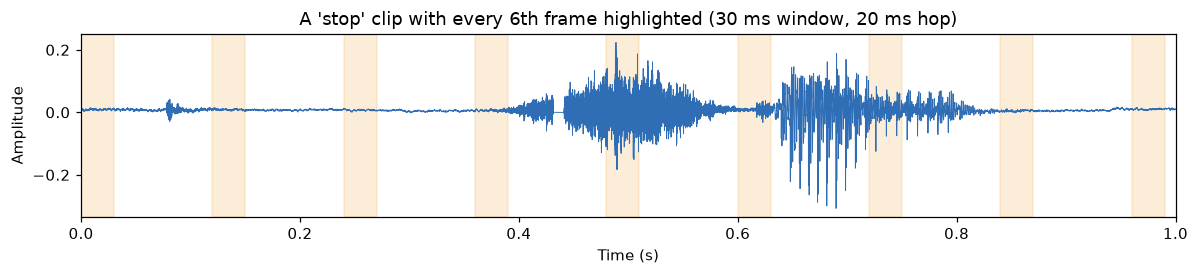

In [8]:
def load_wav(path):
    audio, _ = tf.audio.decode_wav(tf.io.read_file(path), desired_channels=1)
    audio = tf.squeeze(audio, axis=-1)[:CLIP_SAMPLES]
    audio = tf.pad(audio, [[0, CLIP_SAMPLES - tf.shape(audio)[0]]])
    audio.set_shape([CLIP_SAMPLES])
    return audio


example_path = stop_df[stop_df.split == "train"].path.iloc[0]
example_audio = load_wav(example_path)
example_frames = tf.signal.frame(example_audio, FRAME_LENGTH, FRAME_STEP)

print("Example clip     :", Path(example_path).name)
print("Waveform shape   :", tuple(example_audio.shape), "samples")
print("Framed shape     :", tuple(example_frames.shape), "(frames x samples per frame)")
print(f"Frame 0 covers samples 0 to {FRAME_LENGTH - 1}, frame 1 starts at sample {FRAME_STEP}")

fig, ax = plt.subplots(figsize=(11, 2.6))
t = np.arange(CLIP_SAMPLES) / SAMPLE_RATE
ax.plot(t, example_audio.numpy(), color="#2f6db5", lw=0.6)
for f in range(0, NUM_FRAMES, 6):
    start = f * FRAME_STEP / SAMPLE_RATE
    ax.axvspan(start, start + WINDOW_MS / 1000, color="#f0a030", alpha=0.18)
ax.set(title="A 'stop' clip with every 6th frame highlighted (30 ms window, 20 ms hop)",
       xlabel="Time (s)", ylabel="Amplitude", xlim=(0, 1))
plt.tight_layout()
plt.savefig(OUT_DIR / "framing_example.png", bbox_inches="tight")
plt.show()

## 3. Show what the machine "hears" (features)

For every frame:

1. A Hann window is applied and a 512-point FFT is taken (STFT). The magnitude gives the **spectrogram** (49 frames × 257 frequency bins, 0 to 8 kHz).
2. 40 **mel filters** from 20 Hz to 7.6 kHz group the bins the way human hearing does (fine at low frequencies, coarse at high frequencies). The log of each filter output is taken. The upper edge is kept high on purpose: the hissing "s" at the start of "stop" has most of its energy between 4 and 8 kHz, and a 4 kHz limit would throw that clue away.
3. A **DCT** of the 40 log-mel values gives the cepstral coefficients. The first **10 MFCCs** are kept. They describe the overall shape of the spectrum (the vocal tract shape) and drop fine detail such as pitch.

The result is a **49 × 10 MFCC** "image" per clip. Each of the 10 coefficients is then normalized with the mean and standard deviation of the training set, so all inputs are on a similar scale. This also helps the int8 conversion later, because one int8 scale must cover the whole input.

In [9]:
MEL_MATRIX = tf.signal.linear_to_mel_weight_matrix(
    num_mel_bins=NUM_MEL_BINS,
    num_spectrogram_bins=FFT_LENGTH // 2 + 1,
    sample_rate=SAMPLE_RATE,
    lower_edge_hertz=MEL_LOW_HZ,
    upper_edge_hertz=MEL_HIGH_HZ,
)


def get_spectrogram(audio):
    stft = tf.signal.stft(audio, frame_length=FRAME_LENGTH, frame_step=FRAME_STEP,
                          fft_length=FFT_LENGTH, window_fn=tf.signal.hann_window)
    return tf.abs(stft)


def get_mfcc(audio):
    mel = tf.tensordot(get_spectrogram(audio), MEL_MATRIX, 1)
    log_mel = tf.math.log(mel + LOG_OFFSET)
    return tf.signal.mfccs_from_log_mel_spectrograms(log_mel)[..., :NUM_MFCC]


print("Spectrogram shape:", tuple(get_spectrogram(example_audio).shape))
print("MFCC shape       :", tuple(get_mfcc(example_audio).shape))


def clean_audio_dataset(df):
    ds = tf.data.Dataset.from_tensor_slices((df.path.values, df.label_id.values.astype(np.int32)))
    return ds.map(lambda p, y: (load_wav(p), y), num_parallel_calls=tf.data.AUTOTUNE)


def to_mfcc_arrays(df):
    ds = clean_audio_dataset(df).batch(256).map(lambda a, y: (get_mfcc(a), y))
    xs, ys = [], []
    for x, y in ds:
        xs.append(x.numpy())
        ys.append(y.numpy())
    return np.concatenate(xs), np.concatenate(ys)


split_df = {s: dataset_df[dataset_df.split == s].reset_index(drop=True) for s in SPLITS}
mfcc_raw = {}
labels = {}
for s in SPLITS:
    mfcc_raw[s], labels[s] = to_mfcc_arrays(split_df[s])

MFCC_MEAN = mfcc_raw["train"].mean(axis=(0, 1)).astype(np.float32)
MFCC_STD = (mfcc_raw["train"].std(axis=(0, 1)) + 1e-6).astype(np.float32)


def normalize(mfcc):
    return (mfcc - MFCC_MEAN) / MFCC_STD


X = {s: normalize(mfcc_raw[s])[..., np.newaxis].astype(np.float32) for s in SPLITS}
y = labels
for s in SPLITS:
    print(f"{s:<10} X {X[s].shape}  y {y[s].shape}")
print("Training MFCC mean per coefficient:", np.round(MFCC_MEAN, 2))
print("Training MFCC std per coefficient :", np.round(MFCC_STD, 2))

Spectrogram shape: (49, 257)
MFCC shape       : (49, 10)
train      X (2385, 49, 10, 1)  y (2385,)
validation X (294, 49, 10, 1)  y (294,)
test       X (321, 49, 10, 1)  y (321,)
Training MFCC mean per coefficient: [-2.465e+01  1.090e+00  6.000e-01  2.200e-01 -1.100e-01  2.800e-01
  1.100e-01  1.500e-01 -2.000e-02  1.400e-01]
Training MFCC std per coefficient : [21.77  4.34  2.4   1.56  1.54  1.14  1.08  0.91  0.85  0.76]


### 3.1 Waveform, spectrogram and MFCC: "stop" vs "go"

For each word, the example is the loudest training clip (highest RMS) that is not clipped (peak below 0.95), so the patterns are easy to see without distortion.

stop  example: 39a12648_nohash_1.wav
go    example: 179a61b7_nohash_0.wav


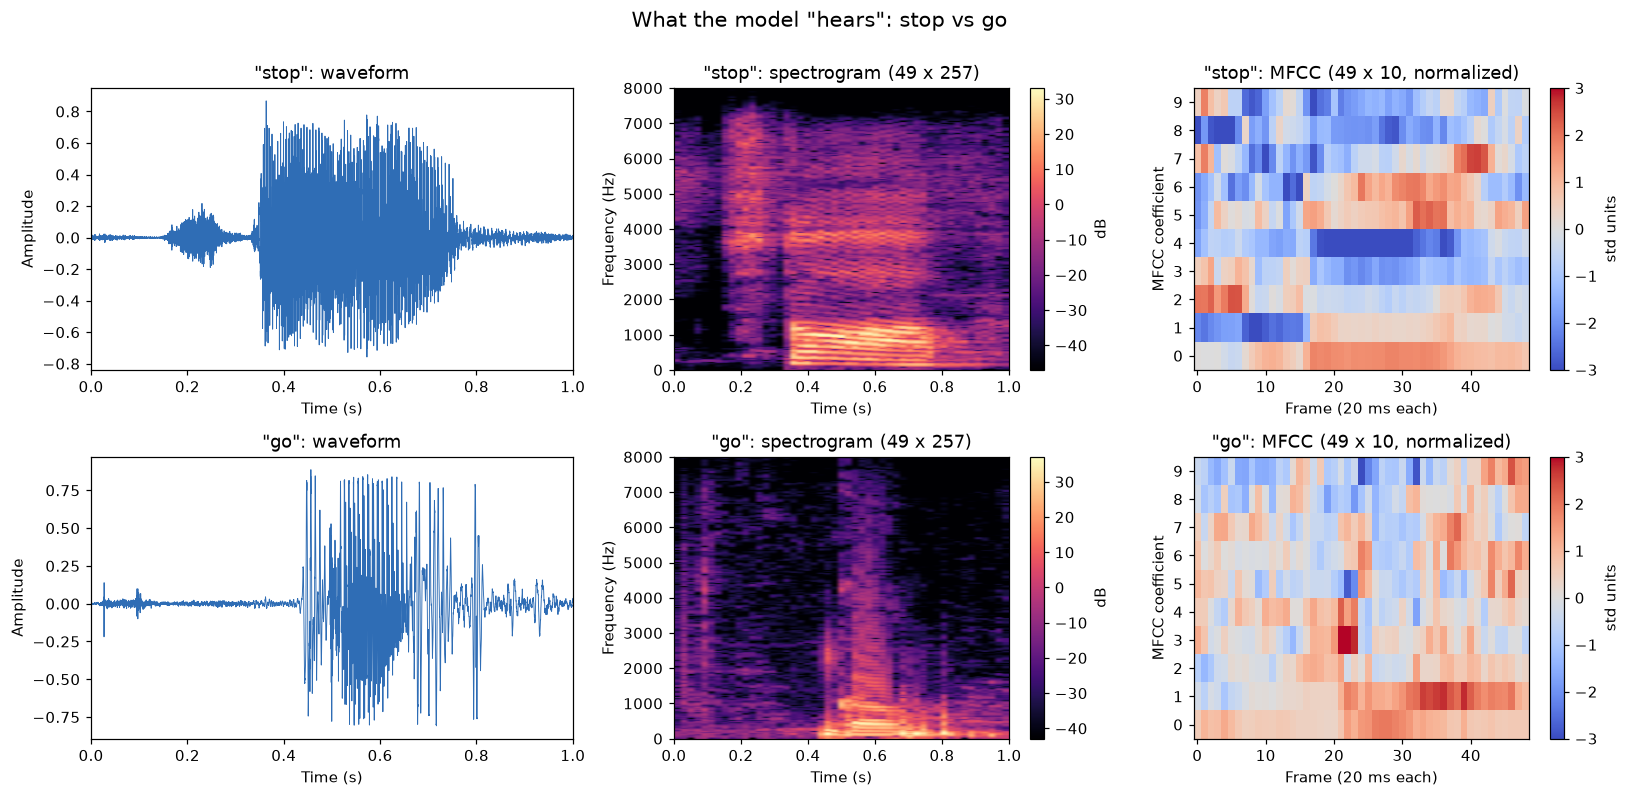

In [10]:
def loudest_clip(word):
    paths = speech_df[(speech_df.word == word) & (speech_df.split == "train")].path.values[:300]
    audios = [load_wav(p).numpy() for p in paths]
    rms = [np.sqrt(np.mean(a ** 2)) if np.abs(a).max() < 0.95 else 0.0 for a in audios]
    best = int(np.argmax(rms))
    return paths[best], audios[best]


fig, axes = plt.subplots(2, 3, figsize=(15, 7.2), gridspec_kw={"width_ratios": [1.15, 1, 1]})
for row, word in enumerate(["stop", "go"]):
    path, audio = loudest_clip(word)
    spec_db = 20 * np.log10(get_spectrogram(audio).numpy() + 1e-6)
    mfcc_n = normalize(get_mfcc(audio).numpy())

    ax = axes[row, 0]
    ax.plot(np.arange(CLIP_SAMPLES) / SAMPLE_RATE, audio, color="#2f6db5", lw=0.6)
    ax.set(title=f'"{word}": waveform', xlabel="Time (s)", ylabel="Amplitude", xlim=(0, 1))

    ax = axes[row, 1]
    im = ax.imshow(spec_db.T, origin="lower", aspect="auto", cmap="magma",
                   extent=[0, 1, 0, SAMPLE_RATE / 2], vmin=spec_db.max() - 80, vmax=spec_db.max())
    ax.set(title=f'"{word}": spectrogram ({spec_db.shape[0]} x {spec_db.shape[1]})',
           xlabel="Time (s)", ylabel="Frequency (Hz)")
    fig.colorbar(im, ax=ax, label="dB")

    ax = axes[row, 2]
    im = ax.imshow(mfcc_n.T, origin="lower", aspect="auto", cmap="coolwarm", vmin=-3, vmax=3,
                   extent=[-0.5, NUM_FRAMES - 0.5, -0.5, NUM_MFCC - 0.5])
    ax.set(title=f'"{word}": MFCC ({mfcc_n.shape[0]} x {mfcc_n.shape[1]}, normalized)',
           xlabel="Frame (20 ms each)", ylabel="MFCC coefficient")
    ax.set_yticks(range(NUM_MFCC))
    fig.colorbar(im, ax=ax, label="std units")
    print(f'{word:<5} example: {Path(path).name}')

plt.suptitle('What the model "hears": stop vs go', fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig(OUT_DIR / "stop_vs_go_features.png", bbox_inches="tight")
plt.show()

**Why the MFCC pictures look different (for the manager, in 3 lines):**

1. "Stop" begins with a hissing "s" (about 0.15 to 0.3 s) whose energy sits high, from about 3 to 7.5 kHz, so the first MFCC block (frames 5 to 15) has coefficient 1 strongly negative (blue), which is the sign of sound tilted toward high frequencies.
2. After a short gap for the "t", the vowel "o" brings strong low-frequency energy, so coefficient 0 turns red and the picture changes to a second, different block: "stop" looks like "hiss block, then vowel block".
3. "Go" has no hiss and no gap: the voiced "g" runs straight into one long "o" vowel below about 1.5 kHz, so its MFCC is a single block, and this "hiss then vowel" versus "vowel only" difference is what the DS-CNN learns.

### 3.2 Average MFCC per class (training set)

Averaging all training MFCCs of a class removes speaker differences and shows the typical pattern each class has.

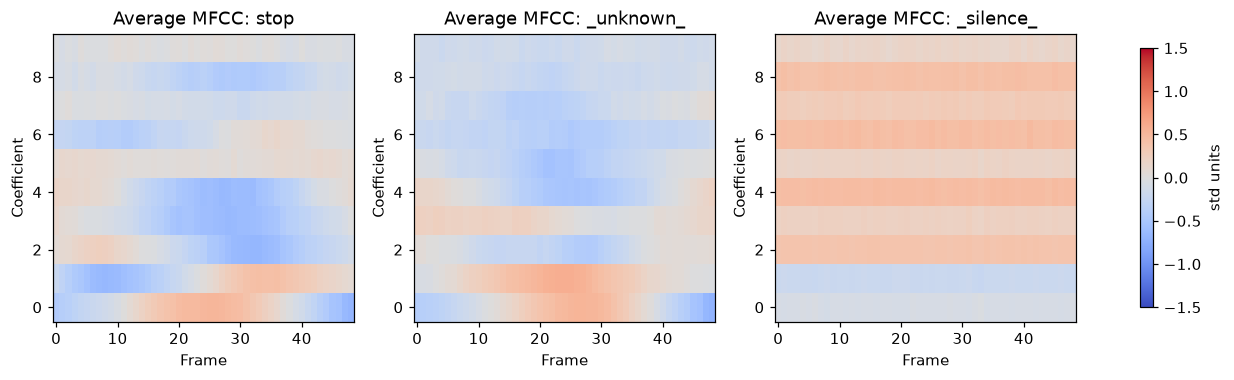

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for i, name in enumerate(LABELS):
    avg = X["train"][y["train"] == i, :, :, 0].mean(axis=0)
    im = axes[i].imshow(avg.T, origin="lower", aspect="auto", cmap="coolwarm", vmin=-1.5, vmax=1.5)
    axes[i].set(title=f"Average MFCC: {name}", xlabel="Frame", ylabel="Coefficient")
fig.colorbar(im, ax=axes, label="std units", shrink=0.9)
plt.savefig(OUT_DIR / "average_mfcc_per_class.png", bbox_inches="tight")
plt.show()

\_silence\_ is flat over time (horizontal stripes) because machine noise does not change from frame to frame, while both word classes have a vowel bump in the middle frames. The average "stop" and \_unknown\_ pictures differ less than single clips do, because \_unknown\_ mixes 7 words; this is why a trained model is needed instead of a simple template.

## 4. Design the brain (KWS architecture)

The model is the small DS-CNN from the "Hello Edge: Keyword Spotting on Microcontrollers" paper (Zhang et al., ARM, 2017):

| Layer | Details | Output shape |
|---|---|---|
| Input | normalized MFCC | 49 × 10 × 1 |
| Conv2D | 64 filters, 10 × 4 kernel, stride 2, BN, ReLU | 25 × 5 × 64 |
| 4 × DS block | depthwise 3 × 3 + BN + ReLU, then pointwise 1 × 1 (64 filters) + BN + ReLU | 25 × 5 × 64 |
| Global average pooling | one value per channel | 64 |
| Dropout 0.4, Dense, softmax | stop, \_unknown\_, \_silence\_ | 3 |

A normal 3 × 3 convolution with 64 inputs and 64 outputs needs 3 × 3 × 64 × 64 = 36,864 weights. The depthwise separable version needs 3 × 3 × 64 + 64 × 64 = 4,672 weights, about 8 times fewer. This is why DS-CNN fits on a microcontroller.

In [12]:
def build_dscnn(input_shape=(NUM_FRAMES, NUM_MFCC, 1), num_classes=len(LABELS), filters=64, num_blocks=4):
    inputs = keras.Input(shape=input_shape, name="mfcc")
    x = layers.Conv2D(filters, (10, 4), strides=(2, 2), padding="same", use_bias=False, name="conv1")(inputs)
    x = layers.BatchNormalization(momentum=0.9, name="conv1_bn")(x)
    x = layers.ReLU(name="conv1_relu")(x)
    for b in range(1, num_blocks + 1):
        x = layers.DepthwiseConv2D((3, 3), padding="same", use_bias=False, name=f"ds{b}_depthwise")(x)
        x = layers.BatchNormalization(momentum=0.9, name=f"ds{b}_dw_bn")(x)
        x = layers.ReLU(name=f"ds{b}_dw_relu")(x)
        x = layers.Conv2D(filters, (1, 1), use_bias=False, name=f"ds{b}_pointwise")(x)
        x = layers.BatchNormalization(momentum=0.9, name=f"ds{b}_pw_bn")(x)
        x = layers.ReLU(name=f"ds{b}_pw_relu")(x)
    x = layers.GlobalAveragePooling2D(name="avg_pool")(x)
    x = layers.Dropout(0.4, name="dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="classifier")(x)
    return keras.Model(inputs, outputs, name="ds_cnn_kws")


model = build_dscnn()
model.summary()

Model: "ds_cnn_kws"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mfcc (InputLayer)               │ (None, 49, 10, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 25, 5, 64)      │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 25, 5, 64)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 25, 5, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_depthwise (DepthwiseConv2D) │ (None, 25, 5, 64)      │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_dw_bn (BatchNormalization)  │ (None, 25, 5, 64)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_dw_relu (ReLU)              │ (None, 25, 5, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_pointwise (Conv2D)          │ (None, 25, 5, 64)      │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_pw_bn (BatchNormalization)  │ (None, 25, 5, 64)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_pw_relu (ReLU)              │ (None, 25, 5, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_depthwise (DepthwiseConv2D) │ (None, 25, 5, 64)      │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_dw_bn (BatchNormalization)  │ (None, 25, 5, 64)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_dw_relu (ReLU)              │ (None, 25, 5, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_pointwise (Conv2D)          │ (None, 25, 5, 64)      │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_pw_bn (BatchNormalization)  │ (None, 25, 5, 64)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_pw_relu (ReLU)              │ (None, 25, 5, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_depthwise (DepthwiseConv2D) │ (None, 25, 5, 64)      │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_dw_bn (BatchNormalization)  │ (None, 25, 5, 64)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_dw_relu (ReLU)              │ (None, 25, 5, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_pointwise (Conv2D)          │ (None, 25, 5, 64)      │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_pw_bn (BatchNormalization)  │ (None, 25, 5, 64)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_pw_relu (ReLU)              │ (None, 25, 5, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds4_depthwise (DepthwiseConv2D) │ (None, 25, 5, 64)      │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds4_dw_bn (BatchNormalization)  │ (None, 25, 5, 64)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds4_dw_relu (ReLU)              │ (None, 25, 5, 64)      │             

 Total params: 23,747 (92.76 KB)

 Trainable params: 22,595 (88.26 KB)

 Non-trainable params: 1,152 (4.50 KB)

In [13]:
total_params = model.count_params()
trainable_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))
non_trainable_params = total_params - trainable_params
bn_params = int(sum(np.prod(w.shape) for l in model.layers if isinstance(l, layers.BatchNormalization) for w in l.weights))
deploy_params = total_params - bn_params

largest_activation = max(
    int(np.prod(l.output.shape[1:])) for l in model.layers if not isinstance(l, keras.layers.InputLayer)
)

param_table = pd.DataFrame({
    "value": [
        f"{total_params:,}",
        f"{trainable_params:,}",
        f"{non_trainable_params:,}",
        f"{deploy_params:,}",
        f"{total_params * 4 / 1024:.1f} KB",
        f"{deploy_params / 1024:.1f} KB (+ small int32 biases and file overhead)",
        f"{largest_activation:,} values = {largest_activation / 1024:.1f} KB in int8",
    ]
}, index=[
    "Total parameters",
    "Trainable parameters",
    "Non-trainable parameters (BN moving mean and variance)",
    "Parameters left after BN is folded into the convolutions",
    "Estimated size in float32 (4 bytes per parameter)",
    "Estimated weight size in int8 (1 byte per parameter)",
    "Largest activation tensor (working RAM, not model storage)",
])
display(param_table)

print(f"Will it fit in under 100 KB? float32 is about {total_params * 4 / 1024:.0f} KB, which is right at the limit "
      f"with no space left for anything else. In int8 the weights take about {deploy_params / 1024:.0f} KB, "
      f"so it fits easily. The exact file sizes are measured in section 7.")

,value
Total parameters,"23,747"
Trainable parameters,"22,595"
Non-trainable parameters (BN moving mean and variance),"1,152"
Parameters left after BN is folded into the convolutions,"21,443"
Estimated size in float32 (4 bytes per parameter),92.8 KB
Estimated weight size in int8 (1 byte per parameter),20.9 KB (+ small int32 biases and file overhead)
"Largest activation tensor (working RAM, not model storage)","8,000 values = 7.8 KB in int8"


Will it fit in under 100 KB? float32 is about 93 KB, which is right at the limit with no space left for anything else. In int8 the weights take about 21 KB, so it fits easily. The exact file sizes are measured in section 7.


## 5. Teach it (training workflow)

Augmentation is applied only to the training audio, on the fly, so every epoch sees new versions of each clip:

- **Time shift:** the clip is moved by a random amount between −100 ms and +100 ms, and the empty part is filled with zeros. This covers workers who say "stop" a little early or late inside the 1-second window.
- **Background noise:** with probability 0.8, a random 1-second crop of the *training* factory noise is added at a random SNR between 0 dB (noise as loud as the speech) and 20 dB (quiet background). This covers a loud factory floor.

Then the MFCC is computed and normalized with the training mean and standard deviation. Validation and test clips are never augmented.

The optimizer is Adam with a learning rate that is halved when validation loss stops improving. Training stops early when validation accuracy has not improved for 12 epochs, and the best weights are kept.

In [14]:
TRAIN_NOISE = tf.constant(noise_banks["train"])
NOISE_LEN = int(TRAIN_NOISE.shape[1])
MFCC_MEAN_TF = tf.constant(MFCC_MEAN)
MFCC_STD_TF = tf.constant(MFCC_STD)


def time_shift(audio):
    shift = tf.random.uniform([], -MAX_SHIFT, MAX_SHIFT + 1, dtype=tf.int32)
    shifted = tf.roll(audio, shift, axis=0)
    idx = tf.range(CLIP_SAMPLES)
    keep = tf.logical_and(idx >= shift, idx < CLIP_SAMPLES + shift)
    return tf.where(keep, shifted, tf.zeros_like(shifted))


def mix_noise(audio, noise_bank, snr_db):
    k = tf.random.uniform([], 0, tf.shape(noise_bank)[0], dtype=tf.int32)
    start = tf.random.uniform([], 0, tf.shape(noise_bank)[1] - CLIP_SAMPLES, dtype=tf.int32)
    noise = noise_bank[k, start:start + CLIP_SAMPLES]
    signal_rms = tf.sqrt(tf.reduce_mean(tf.square(audio))) + 1e-5
    noise_rms = tf.sqrt(tf.reduce_mean(tf.square(noise))) + 1e-9
    noise = noise * (signal_rms / noise_rms) / tf.pow(10.0, snr_db / 20.0)
    return tf.clip_by_value(audio + noise, -1.0, 1.0)


def augment(audio, label):
    audio = time_shift(audio)
    snr_db = tf.random.uniform([], SNR_RANGE_DB[0], SNR_RANGE_DB[1])
    audio = tf.cond(tf.random.uniform([]) < NOISE_PROB,
                    lambda: mix_noise(audio, TRAIN_NOISE, snr_db),
                    lambda: audio)
    return audio, label


def audio_to_model_input(audio, label):
    mfcc = (get_mfcc(audio) - MFCC_MEAN_TF) / MFCC_STD_TF
    return mfcc[..., tf.newaxis], label


train_ds = (clean_audio_dataset(split_df["train"])
            .cache()
            .shuffle(len(split_df["train"]), seed=SEED, reshuffle_each_iteration=True)
            .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE)
            .map(audio_to_model_input, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((X["validation"], y["validation"])).batch(BATCH_SIZE)

xb, yb = next(iter(train_ds))
print("One training batch:", tuple(xb.shape), tuple(yb.shape))

One training batch: (64, 49, 10, 1) (64,)


### 5.1 What augmentation does to one clip

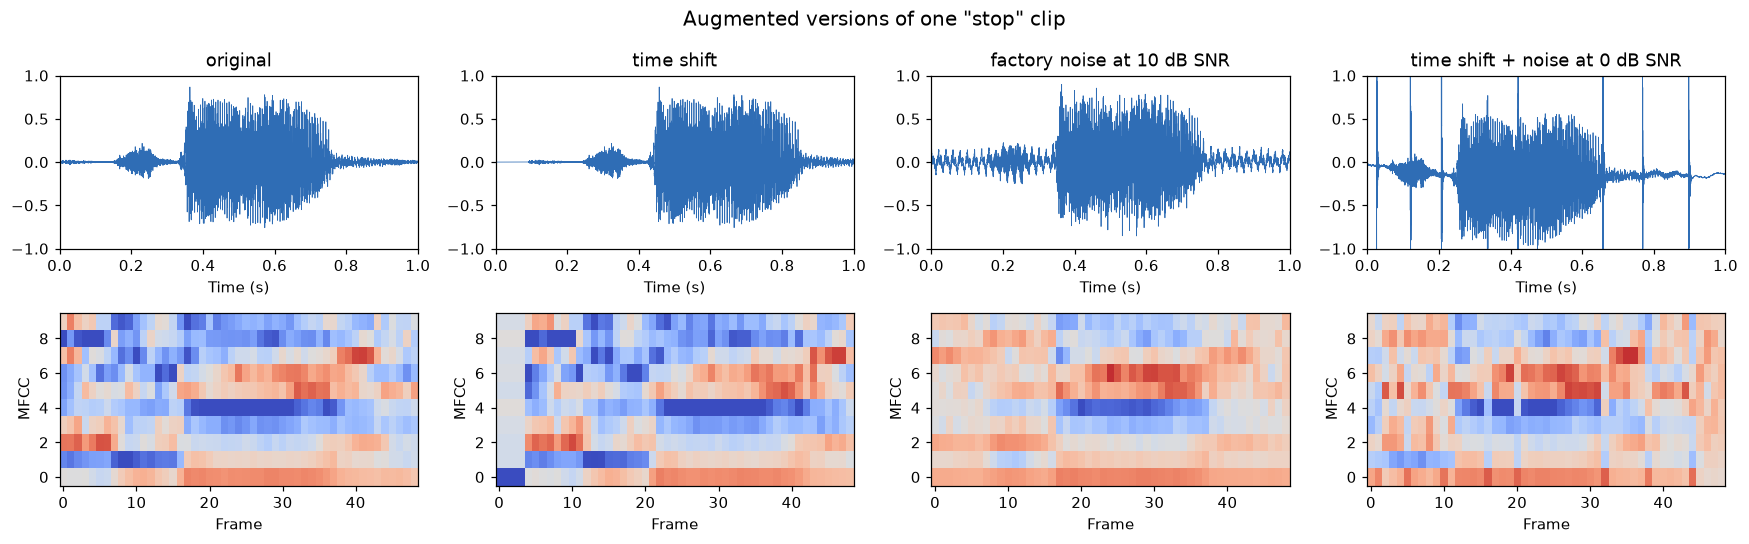

In [15]:
demo_path, demo_audio = loudest_clip("stop")
demo_audio = tf.constant(demo_audio)
tf.random.set_seed(SEED)
versions = {
    "original": demo_audio,
    "time shift": time_shift(demo_audio),
    "factory noise at 10 dB SNR": mix_noise(demo_audio, TRAIN_NOISE, 10.0),
    "time shift + noise at 0 dB SNR": mix_noise(time_shift(demo_audio), TRAIN_NOISE, 0.0),
}
fig, axes = plt.subplots(2, 4, figsize=(16, 5))
for i, (name, a) in enumerate(versions.items()):
    axes[0, i].plot(np.arange(CLIP_SAMPLES) / SAMPLE_RATE, a.numpy(), lw=0.5, color="#2f6db5")
    axes[0, i].set(title=name, xlim=(0, 1), ylim=(-1, 1), xlabel="Time (s)")
    m = normalize(get_mfcc(a).numpy())
    axes[1, i].imshow(m.T, origin="lower", aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
    axes[1, i].set(xlabel="Frame", ylabel="MFCC")
plt.suptitle('Augmented versions of one "stop" clip', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / "augmentation_examples.png", bbox_inches="tight")
plt.show()

### 5.2 Train the DS-CNN

In [16]:
keras.utils.set_random_seed(SEED)
model = build_dscnn()
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=12, restore_best_weights=True, verbose=1),
]

start = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)
train_minutes = (time.time() - start) / 60
best_epoch = int(np.argmax(history.history["val_accuracy"])) + 1
print(f"\nTraining time: {train_minutes:.1f} min | epochs run: {len(history.history['loss'])} | "
      f"best epoch: {best_epoch} | best validation accuracy: {max(history.history['val_accuracy']):.4f}")
model.save(OUT_DIR / "kws_dscnn_float.keras")

Epoch 1/60
38/38 - 2s - 64ms/step - accuracy: 0.6591 - loss: 0.8099 - val_accuracy: 0.3333 - val_loss: 1.3189 - learning_rate: 0.0010
Epoch 2/60
38/38 - 1s - 15ms/step - accuracy: 0.8792 - loss: 0.3938 - val_accuracy: 0.9354 - val_loss: 0.2001 - learning_rate: 0.0010
Epoch 3/60
38/38 - 1s - 15ms/step - accuracy: 0.9275 - loss: 0.2487 - val_accuracy: 0.9524 - val_loss: 0.1540 - learning_rate: 0.0010
Epoch 4/60
38/38 - 1s - 15ms/step - accuracy: 0.9472 - loss: 0.1840 - val_accuracy: 0.9558 - val_loss: 0.1289 - learning_rate: 0.0010
Epoch 5/60
38/38 - 1s - 16ms/step - accuracy: 0.9505 - loss: 0.1504 - val_accuracy: 0.9592 - val_loss: 0.1327 - learning_rate: 0.0010
Epoch 6/60
38/38 - 1s - 15ms/step - accuracy: 0.9535 - loss: 0.1499 - val_accuracy: 0.9388 - val_loss: 0.1396 - learning_rate: 0.0010
Epoch 7/60
38/38 - 1s - 16ms/step - accuracy: 0.9631 - loss: 0.1213 - val_accuracy: 0.9592 - val_loss: 0.0938 - learning_rate: 0.0010
Epoch 8/60
38/38 - 1s - 15ms/step - accuracy: 0.9690 - loss: 0

### 5.3 Accuracy and loss curves

Training accuracy is computed on augmented (noisy, shifted) audio while validation uses clean audio, so validation accuracy can be higher than training accuracy. That is expected and is not a bug.

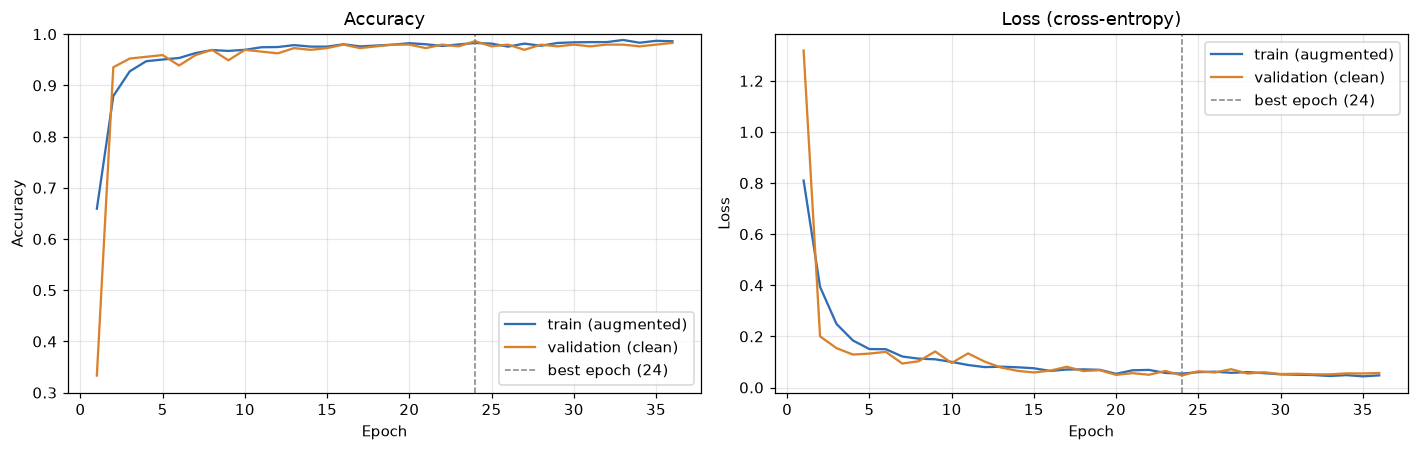

In [17]:
h = history.history
epochs_axis = np.arange(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(epochs_axis, h["accuracy"], label="train (augmented)", color="#2f6db5")
axes[0].plot(epochs_axis, h["val_accuracy"], label="validation (clean)", color="#d9822b")
axes[0].axvline(best_epoch, color="gray", ls="--", lw=1, label=f"best epoch ({best_epoch})")
axes[0].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0.3, 1.0))
axes[1].plot(epochs_axis, h["loss"], label="train (augmented)", color="#2f6db5")
axes[1].plot(epochs_axis, h["val_loss"], label="validation (clean)", color="#d9822b")
axes[1].axvline(best_epoch, color="gray", ls="--", lw=1, label=f"best epoch ({best_epoch})")
axes[1].set(title="Loss (cross-entropy)", xlabel="Epoch", ylabel="Loss")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "training_curves.png", bbox_inches="tight")
plt.show()

## 6. Safety check (evaluation on unseen speakers)

- **Miss:** a real "stop" is predicted as \_unknown\_ or \_silence\_. The belt keeps running. **Dangerous.**
- **False alarm:** an \_unknown\_ word or \_silence\_ noise is predicted as "stop". The line halts for no reason. **Costly.**

From the confusion matrix (rows = true class, columns = predicted class): misses are the off-diagonal cells of the "stop" row, and false alarms are the off-diagonal cells of the "stop" column.

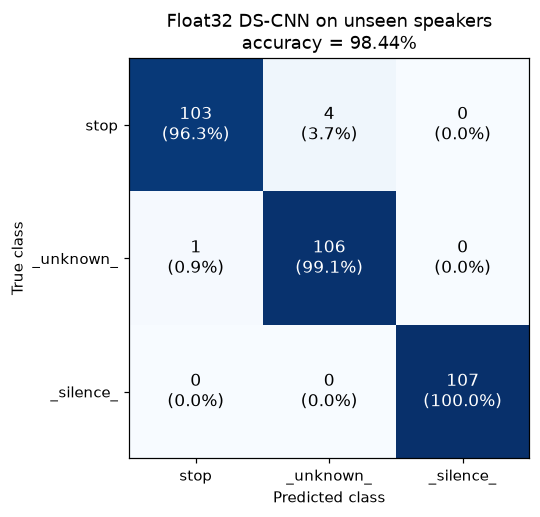

,test clips,correct,recall (%),precision (%)
stop,107,103,96.26,99.04
_unknown_,107,106,99.07,96.36
_silence_,107,107,100.00,100.00


In [18]:
def confusion(y_true, y_pred, n=len(LABELS)):
    cm = np.zeros((n, n), dtype=int)
    for t_, p_ in zip(y_true, y_pred):
        cm[t_, p_] += 1
    return cm


def safety_numbers(cm):
    n_stop = cm[STOP_ID].sum()
    n_other = cm.sum() - n_stop
    misses = n_stop - cm[STOP_ID, STOP_ID]
    false_alarms = cm[:, STOP_ID].sum() - cm[STOP_ID, STOP_ID]
    return {
        "accuracy": np.trace(cm) / cm.sum(),
        "misses": int(misses), "stop_clips": int(n_stop), "miss_rate": misses / n_stop,
        "false_alarms": int(false_alarms), "other_clips": int(n_other), "false_alarm_rate": false_alarms / n_other,
    }


def plot_confusion(cm, title, path):
    fig, ax = plt.subplots(figsize=(5.6, 4.8))
    ax.imshow(cm, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            pct = cm[i, j] / cm[i].sum() * 100
            ax.text(j, i, f"{cm[i, j]}\n({pct:.1f}%)", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
    ax.set_xticks(range(len(LABELS)), LABELS)
    ax.set_yticks(range(len(LABELS)), LABELS)
    ax.set(xlabel="Predicted class", ylabel="True class", title=title)
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    plt.show()


test_probs_float = model.predict(X["test"], batch_size=256, verbose=0)
test_pred_float = test_probs_float.argmax(axis=1)
cm_float = confusion(y["test"], test_pred_float)
float_safety = safety_numbers(cm_float)

plot_confusion(cm_float, f"Float32 DS-CNN on unseen speakers\naccuracy = {float_safety['accuracy'] * 100:.2f}%",
               OUT_DIR / "confusion_matrix_float.png")

per_class = pd.DataFrame({
    "test clips": cm_float.sum(axis=1),
    "correct": np.diag(cm_float),
    "recall (%)": np.round(np.diag(cm_float) / cm_float.sum(axis=1) * 100, 2),
    "precision (%)": np.round(np.diag(cm_float) / cm_float.sum(axis=0) * 100, 2),
}, index=LABELS)
display(per_class)

In [19]:
fa_from_unknown = int(cm_float[LABEL_TO_ID["_unknown_"], STOP_ID])
fa_from_silence = int(cm_float[LABEL_TO_ID["_silence_"], STOP_ID])
print("SAFETY REPORT (float32 model, test set of unseen speakers)")
print(f"  Test accuracy : {float_safety['accuracy'] * 100:.2f}%")
print(f"  Misses        : {float_safety['misses']} of {float_safety['stop_clips']} 'stop' clips "
      f"({float_safety['miss_rate'] * 100:.1f}%)  -> belt would keep running")
print(f"  False alarms  : {float_safety['false_alarms']} of {float_safety['other_clips']} other clips "
      f"({float_safety['false_alarm_rate'] * 100:.1f}%)  -> line would halt for no reason")
print(f"                  ({fa_from_unknown} from other words, {fa_from_silence} from factory noise)")

missed_words = split_df["test"][(y["test"] == STOP_ID) & (test_pred_float != STOP_ID)]
fa_words = split_df["test"][(y["test"] != STOP_ID) & (test_pred_float == STOP_ID)]
if len(fa_words):
    print("\nWhich clips caused false alarms:", fa_words.word.value_counts().to_dict())

SAFETY REPORT (float32 model, test set of unseen speakers)
  Test accuracy : 98.44%
  Misses        : 4 of 107 'stop' clips (3.7%)  -> belt would keep running
  False alarms  : 1 of 214 other clips (0.5%)  -> line would halt for no reason
                  (1 from other words, 0 from factory noise)

Which clips caused false alarms: {'go': 1}


### 6.1 The safety trade-off: changing the "stop" threshold

The model outputs a probability for "stop". Above, the class with the highest probability wins. On the machine we can instead say: halt the belt only if P(stop) ≥ threshold. A **lower threshold** catches more "stop" words (fewer misses) but halts the line more often by mistake. A **higher threshold** does the opposite.

,misses,miss rate (%),false alarms,false alarm rate (%)
threshold,,,,
0.1,1,0.9,3,1.4
0.3,2,1.9,2,0.9
0.5,4,3.7,1,0.5
0.7,5,4.7,0,0.0
0.9,7,6.5,0,0.0


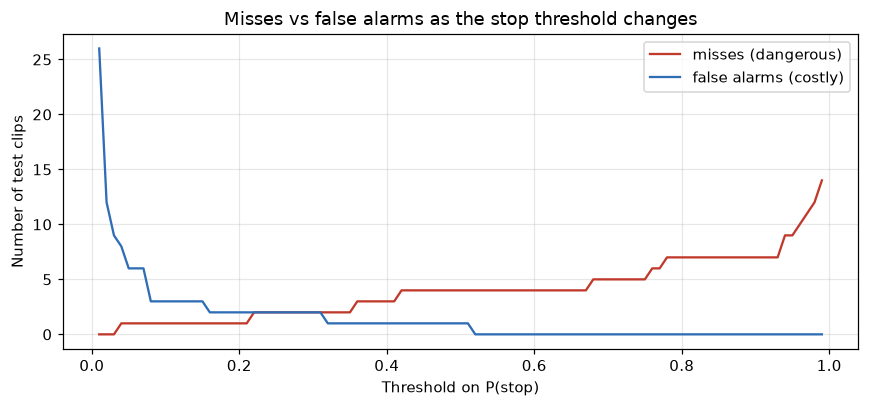

In [20]:
p_stop = test_probs_float[:, STOP_ID]
is_stop = y["test"] == STOP_ID
sweep = []
for th in [0.1, 0.3, 0.5, 0.7, 0.9]:
    fired = p_stop >= th
    sweep.append({
        "threshold": th,
        "misses": int((is_stop & ~fired).sum()),
        "miss rate (%)": round((is_stop & ~fired).sum() / is_stop.sum() * 100, 1),
        "false alarms": int((~is_stop & fired).sum()),
        "false alarm rate (%)": round((~is_stop & fired).sum() / (~is_stop).sum() * 100, 1),
    })
sweep_df = pd.DataFrame(sweep).set_index("threshold")
sweep_df.to_csv(OUT_DIR / "threshold_sweep_float.csv")
display(sweep_df)

ths = np.linspace(0.01, 0.99, 99)
miss_curve = [(is_stop & (p_stop < t_)).sum() for t_ in ths]
fa_curve = [(~is_stop & (p_stop >= t_)).sum() for t_ in ths]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(ths, miss_curve, color="#c0392b", label="misses (dangerous)")
ax.plot(ths, fa_curve, color="#2f6db5", label="false alarms (costly)")
ax.set(xlabel="Threshold on P(stop)", ylabel="Number of test clips",
       title="Misses vs false alarms as the stop threshold changes")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "threshold_tradeoff.png", bbox_inches="tight")
plt.show()

For a safety stop, a miss is far worse than a false alarm: a miss can cost a finger, while a false alarm costs a few seconds of production. So the threshold should stay low enough that misses are close to zero, and false alarms are then reduced in Lab 6 with smoothing over several windows and a refractory period, not by raising the threshold. The voice stop is also an extra layer: the red emergency button stays in place.

### 6.2 Extra check: test speakers in factory noise

The test clips above are clean recordings. The factory is loud, so the same test set is mixed with the **test** noise recordings (never used in training) at different SNRs.

In [21]:
TEST_NOISE = tf.constant(noise_banks["test"])
test_audio = np.stack([load_wav(p).numpy() for p in split_df["test"].path])

noise_rows = []
for snr in [20, 10, 5, 0]:
    tf.random.set_seed(SEED)
    noisy = tf.stack([mix_noise(tf.constant(a), TEST_NOISE, float(snr)) for a in test_audio])
    xn = normalize(get_mfcc(noisy).numpy())[..., np.newaxis]
    s = safety_numbers(confusion(y["test"], model.predict(xn, batch_size=256, verbose=0).argmax(axis=1)))
    noise_rows.append({"SNR (dB)": snr, "accuracy (%)": round(s["accuracy"] * 100, 2),
                       "misses": s["misses"], "false alarms": s["false_alarms"]})
noise_df = pd.DataFrame([{"SNR (dB)": "clean", "accuracy (%)": round(float_safety["accuracy"] * 100, 2),
                          "misses": float_safety["misses"], "false alarms": float_safety["false_alarms"]}]
                        + noise_rows).set_index("SNR (dB)")
noise_df.to_csv(OUT_DIR / "noise_robustness.csv")
display(noise_df)

,accuracy (%),misses,false alarms
SNR (dB),,,
clean,98.44,4,1
20,98.13,4,2
10,97.82,7,0
5,96.57,9,1
0,94.70,12,2


## 7. Make it fit the chip (deployment preparation)

Two TensorFlow Lite models are made:

1. **float32 TFLite:** same weights as the Keras model, used as the baseline.
2. **Full int8 TFLite:** weights, activations, input and output are all 8-bit integers, which is what microcontroller libraries such as TensorFlow Lite for Microcontrollers run fastest. The converter needs a **representative dataset** to find the range of every activation. Here it gets 500 training inputs: 250 clean and 250 augmented (noisy and shifted), so the ranges also cover a loud factory.

To feed the int8 model, the normalized MFCC is quantized with the model's input scale and zero point: `q = round(x / scale) + zero_point`, clipped to [−128, 127]. The int8 output is turned back into probabilities with `p = (q − zero_point) × scale`.

In [22]:
SAVED_MODEL_DIR = OUT_DIR / "saved_model"
with contextlib.redirect_stdout(io.StringIO()):
    model.export(str(SAVED_MODEL_DIR), format="tf_saved_model")

converter = tf.lite.TFLiteConverter.from_saved_model(str(SAVED_MODEL_DIR))
tflite_float = converter.convert()

rep_rng = np.random.default_rng(SEED)
rep_clean = X["train"][rep_rng.choice(len(X["train"]), 250, replace=False)]
rep_aug = np.concatenate([xb.numpy() for xb, _ in train_ds.take(4)])[:250]
rep_data = np.concatenate([rep_clean, rep_aug]).astype(np.float32)


def representative_dataset():
    for i in range(len(rep_data)):
        yield [rep_data[i:i + 1]]


converter = tf.lite.TFLiteConverter.from_saved_model(str(SAVED_MODEL_DIR))
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
tflite_int8 = converter.convert()

FLOAT_PATH = OUT_DIR / "kws_float32.tflite"
INT8_PATH = OUT_DIR / "kws_int8.tflite"
FLOAT_PATH.write_bytes(tflite_float)
INT8_PATH.write_bytes(tflite_int8)
print(f"float32 TFLite: {len(tflite_float):,} bytes = {len(tflite_float) / 1024:.1f} KB")
print(f"int8 TFLite   : {len(tflite_int8):,} bytes = {len(tflite_int8) / 1024:.1f} KB")

INFO:tensorflow:Assets written to: /Users/Tanmay/Downloads/Lab5_KWS/outputs/saved_model/assets


INFO:tensorflow:Assets written to: /Users/Tanmay/Downloads/Lab5_KWS/outputs/saved_model/assets


float32 TFLite: 97,148 bytes = 94.9 KB
int8 TFLite   : 46,640 bytes = 45.5 KB


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


### 7.1 Check the int8 model and run both TFLite models on the test set

int8 input : [ 1 49 10  1] int8 scale/zero_point = (0.05717320740222931, -9)
int8 output: [1 3] int8 scale/zero_point = (0.00390625, -128)
Operators in the int8 model: ['CONV_2D', 'DEPTHWISE_CONV_2D', 'FULLY_CONNECTED', 'MEAN', 'SOFTMAX']
Tensor data types          : ['int32', 'int8']

int8 and float32 give the same prediction on 99.7% of test clips


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


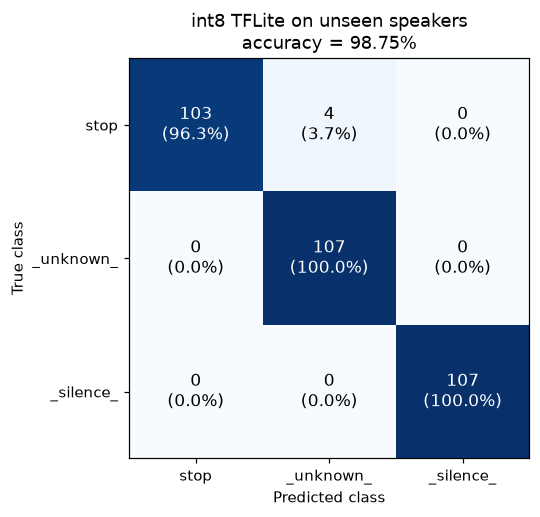

In [23]:
def make_interpreter(model_bytes):
    interp = tf.lite.Interpreter(model_content=model_bytes)
    interp.allocate_tensors()
    return interp


def run_tflite(model_bytes, x):
    interp = make_interpreter(model_bytes)
    inp = interp.get_input_details()[0]
    out = interp.get_output_details()[0]
    probs = np.zeros((len(x), len(LABELS)), dtype=np.float32)
    start = time.perf_counter()
    for i in range(len(x)):
        sample = x[i:i + 1]
        if inp["dtype"] == np.int8:
            scale, zero = inp["quantization"]
            sample = np.clip(np.round(sample / scale) + zero, -128, 127).astype(np.int8)
        interp.set_tensor(inp["index"], sample)
        interp.invoke()
        raw = interp.get_tensor(out["index"])[0]
        if out["dtype"] == np.int8:
            scale, zero = out["quantization"]
            raw = (raw.astype(np.float32) - zero) * scale
        probs[i] = raw
    ms_per_clip = (time.perf_counter() - start) / len(x) * 1000
    return probs, ms_per_clip


interp8 = make_interpreter(tflite_int8)
in_det = interp8.get_input_details()[0]
out_det = interp8.get_output_details()[0]
print("int8 input :", in_det["shape"], in_det["dtype"].__name__, "scale/zero_point =", in_det["quantization"])
print("int8 output:", out_det["shape"], out_det["dtype"].__name__, "scale/zero_point =", out_det["quantization"])
plain_interp = tf.lite.Interpreter(
    model_content=tflite_int8,
    experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
plain_interp.allocate_tensors()
op_types = sorted({d["op_name"] for d in plain_interp._get_ops_details()})
tensor_types = sorted({d["dtype"].__name__ for d in plain_interp.get_tensor_details()})
print("Operators in the int8 model:", op_types)
print("Tensor data types          :", tensor_types)

probs_tfl_float, ms_float = run_tflite(tflite_float, X["test"])
probs_tfl_int8, ms_int8 = run_tflite(tflite_int8, X["test"])
cm_tfl_float = confusion(y["test"], probs_tfl_float.argmax(axis=1))
cm_int8 = confusion(y["test"], probs_tfl_int8.argmax(axis=1))
tfl_float_safety = safety_numbers(cm_tfl_float)
int8_safety = safety_numbers(cm_int8)
agreement = (probs_tfl_int8.argmax(axis=1) == probs_tfl_float.argmax(axis=1)).mean()
print(f"\nint8 and float32 give the same prediction on {agreement * 100:.1f}% of test clips")

plot_confusion(cm_int8, f"int8 TFLite on unseen speakers\naccuracy = {int8_safety['accuracy'] * 100:.2f}%",
               OUT_DIR / "confusion_matrix_int8.png")

### 7.2 Float vs int8 comparison

The inference time below is measured on this laptop's CPU, one clip at a time. A laptop CPU has fast floating-point hardware, so int8 is not always faster here. The int8 speed and memory advantage matters on a microcontroller without a floating-point unit; the timing is measured properly in Lab 6. The `.keras` file is large because it also stores the optimizer state, which the microcontroller never needs.

,size (KB),test accuracy (%),misses,false alarms,ms per clip (laptop)
model,,,,,
Keras float32 (.keras),405.14,98.44,4,1,NaN
TFLite float32,94.87,98.44,4,1,0.04
TFLite int8,45.55,98.75,4,0,0.04


Size: int8 is 2.1x smaller than float32 TFLite (94.9 KB -> 45.5 KB)
Accuracy change float32 -> int8: +0.31 percentage points (within the 1% target)
Fits the 100 KB model budget: YES (54.5 KB left for code and buffers)


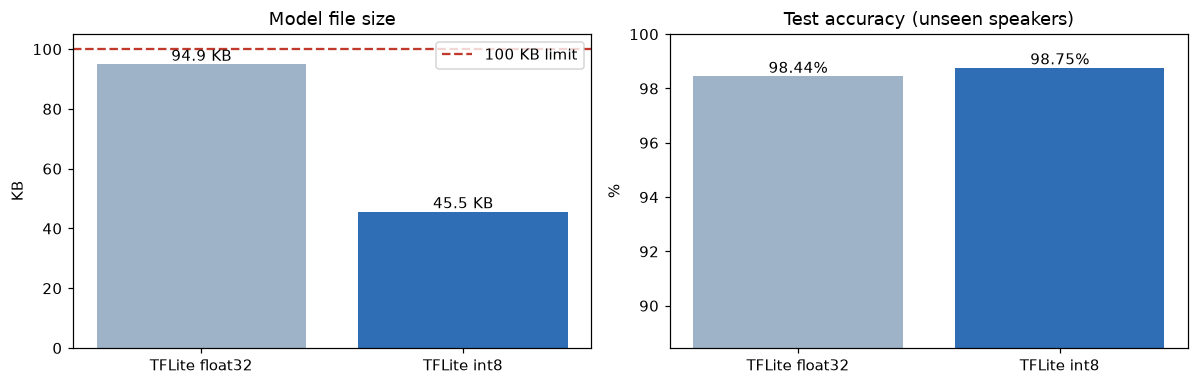

In [24]:
keras_size = (OUT_DIR / "kws_dscnn_float.keras").stat().st_size
comparison = pd.DataFrame([
    {"model": "Keras float32 (.keras)", "size (KB)": keras_size / 1024,
     "test accuracy (%)": float_safety["accuracy"] * 100,
     "misses": float_safety["misses"], "false alarms": float_safety["false_alarms"], "ms per clip (laptop)": np.nan},
    {"model": "TFLite float32", "size (KB)": len(tflite_float) / 1024,
     "test accuracy (%)": tfl_float_safety["accuracy"] * 100,
     "misses": tfl_float_safety["misses"], "false alarms": tfl_float_safety["false_alarms"], "ms per clip (laptop)": ms_float},
    {"model": "TFLite int8", "size (KB)": len(tflite_int8) / 1024,
     "test accuracy (%)": int8_safety["accuracy"] * 100,
     "misses": int8_safety["misses"], "false alarms": int8_safety["false_alarms"], "ms per clip (laptop)": ms_int8},
]).set_index("model").round(2)
comparison.to_csv(OUT_DIR / "float_vs_int8.csv")
display(comparison)

acc_drop = (tfl_float_safety["accuracy"] - int8_safety["accuracy"]) * 100
acc_change = (int8_safety["accuracy"] - tfl_float_safety["accuracy"]) * 100 + 0.0
shrink = len(tflite_float) / len(tflite_int8)
print(f"Size: int8 is {shrink:.1f}x smaller than float32 TFLite "
      f"({len(tflite_float) / 1024:.1f} KB -> {len(tflite_int8) / 1024:.1f} KB)")
print(f"Accuracy change float32 -> int8: {acc_change:+.2f} percentage points "
      f"({'within' if acc_drop < 1 else 'NOT within'} the 1% target)")
print(f"Fits the 100 KB model budget: {'YES' if len(tflite_int8) < 100 * 1024 else 'NO'} "
      f"({100 - len(tflite_int8) / 1024:.1f} KB left for code and buffers)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
names = ["TFLite float32", "TFLite int8"]
sizes = [len(tflite_float) / 1024, len(tflite_int8) / 1024]
accs = [tfl_float_safety["accuracy"] * 100, int8_safety["accuracy"] * 100]
bars = axes[0].bar(names, sizes, color=["#9fb3c8", "#2f6db5"])
axes[0].axhline(100, color="#c0392b", ls="--", label="100 KB limit")
axes[0].bar_label(bars, fmt="%.1f KB")
axes[0].set(title="Model file size", ylabel="KB")
axes[0].legend()
bars = axes[1].bar(names, accs, color=["#9fb3c8", "#2f6db5"])
axes[1].bar_label(bars, fmt="%.2f%%")
axes[1].set(title="Test accuracy (unseen speakers)", ylabel="%", ylim=(min(accs) - 10, 100))
plt.tight_layout()
plt.savefig(OUT_DIR / "float_vs_int8.png", bbox_inches="tight")
plt.show()

### 7.3 Export `kws_int8.tflite` and `kws_config.json` for Lab 6

`kws_config.json` holds everything Lab 6 needs to reproduce the exact same input: the labels, audio settings, MFCC settings, the normalization mean and standard deviation, and the int8 input and output scale and zero point. If any of these differ in Lab 6, the model will receive different numbers than it was trained on and accuracy will drop.

In [25]:
int8_sweep = []
p_stop8 = probs_tfl_int8[:, STOP_ID]
for th in [0.5, 0.7, 0.9]:
    fired = p_stop8 >= th
    int8_sweep.append({"threshold": th,
                       "misses": int((is_stop & ~fired).sum()),
                       "false_alarms": int((~is_stop & fired).sum())})

config = {
    "project": "SafeLine voice emergency stop (Lab 5, Tanmay Gautam, 2548559)",
    "model_file": INT8_PATH.name,
    "labels": LABELS,
    "keyword": KEYWORD,
    "keyword_index": STOP_ID,
    "audio": {
        "sample_rate": SAMPLE_RATE,
        "channels": 1,
        "clip_seconds": 1.0,
        "clip_samples": CLIP_SAMPLES,
        "amplitude_range": [-1.0, 1.0],
        "shorter_clips": "zero-pad at the end to clip_samples",
    },
    "features": {
        "type": "mfcc",
        "window_ms": WINDOW_MS,
        "hop_ms": HOP_MS,
        "frame_length": FRAME_LENGTH,
        "frame_step": FRAME_STEP,
        "fft_length": FFT_LENGTH,
        "window_function": "hann",
        "spectrogram": "magnitude (abs of STFT), no padding at the end",
        "num_mel_bins": NUM_MEL_BINS,
        "mel_low_hz": MEL_LOW_HZ,
        "mel_high_hz": MEL_HIGH_HZ,
        "log_offset": LOG_OFFSET,
        "num_mfcc": NUM_MFCC,
        "num_frames": NUM_FRAMES,
        "implementation": "tf.signal.stft -> tf.signal.linear_to_mel_weight_matrix -> log -> tf.signal.mfccs_from_log_mel_spectrograms, keep first num_mfcc",
    },
    "normalization": {
        "formula": "(mfcc - mean) / std, per coefficient",
        "mean": [round(float(v), 6) for v in MFCC_MEAN],
        "std": [round(float(v), 6) for v in MFCC_STD],
    },
    "input": {
        "shape": [int(v) for v in in_det["shape"]],
        "dtype": "int8",
        "scale": float(in_det["quantization"][0]),
        "zero_point": int(in_det["quantization"][1]),
        "formula": "q = clip(round(x / scale) + zero_point, -128, 127)",
    },
    "output": {
        "shape": [int(v) for v in out_det["shape"]],
        "dtype": "int8",
        "scale": float(out_det["quantization"][0]),
        "zero_point": int(out_det["quantization"][1]),
        "formula": "probability = (q - zero_point) * scale",
    },
    "model": {
        "architecture": "DS-CNN: Conv 10x4 stride 2 (64) + 4 depthwise separable blocks (64) + global average pool + dense softmax",
        "parameters": int(total_params),
        "int8_size_bytes": len(tflite_int8),
        "float32_tflite_size_bytes": len(tflite_float),
    },
    "test_results_unseen_speakers": {
        "test_clips": int(len(y["test"])),
        "float32_accuracy": round(float(tfl_float_safety["accuracy"]), 4),
        "int8_accuracy": round(float(int8_safety["accuracy"]), 4),
        "int8_misses": int8_safety["misses"],
        "int8_false_alarms": int8_safety["false_alarms"],
        "int8_threshold_sweep": int8_sweep,
    },
    "test_split_file": "test_split.csv",
}

CONFIG_PATH = OUT_DIR / "kws_config.json"
CONFIG_PATH.write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))

{
  "project": "SafeLine voice emergency stop (Lab 5, Tanmay Gautam, 2548559)",
  "model_file": "kws_int8.tflite",
  "labels": [
    "stop",
    "_unknown_",
    "_silence_"
  ],
  "keyword": "stop",
  "keyword_index": 0,
  "audio": {
    "sample_rate": 16000,
    "channels": 1,
    "clip_seconds": 1.0,
    "clip_samples": 16000,
    "amplitude_range": [
      -1.0,
      1.0
    ],
    "shorter_clips": "zero-pad at the end to clip_samples"
  },
  "features": {
    "type": "mfcc",
    "window_ms": 30,
    "hop_ms": 20,
    "frame_length": 480,
    "frame_step": 320,
    "fft_length": 512,
    "window_function": "hann",
    "spectrogram": "magnitude (abs of STFT), no padding at the end",
    "num_mel_bins": 40,
    "mel_low_hz": 20.0,
    "mel_high_hz": 7600.0,
    "log_offset": 1e-06,
    "num_mfcc": 10,
    "num_frames": 49,
    "implementation": "tf.signal.stft -> tf.signal.linear_to_mel_weight_matrix -> log -> tf.signal.mfccs_from_log_mel_spectrograms, keep first num_mfcc"
  },
  "n

### 7.4 Re-load test: the exported files work on their own

This cell uses only `kws_int8.tflite` and `kws_config.json` (nothing from the training code) to classify every test clip, the same way Lab 6 will, and checks that it gives the same results as section 7.1. Three random test clips of each class are shown.

In [26]:
cfg = json.loads(CONFIG_PATH.read_text())
lab6_interp = tf.lite.Interpreter(model_path=str(OUT_DIR / cfg["model_file"]))
lab6_interp.allocate_tensors()
lab6_in = lab6_interp.get_input_details()[0]
lab6_out = lab6_interp.get_output_details()[0]
f = cfg["features"]
mel_w = tf.signal.linear_to_mel_weight_matrix(f["num_mel_bins"], f["fft_length"] // 2 + 1,
                                              cfg["audio"]["sample_rate"], f["mel_low_hz"], f["mel_high_hz"])


def classify_file(path):
    audio, _ = tf.audio.decode_wav(tf.io.read_file(path), desired_channels=1)
    audio = tf.squeeze(audio, -1)[:cfg["audio"]["clip_samples"]]
    audio = tf.pad(audio, [[0, cfg["audio"]["clip_samples"] - tf.shape(audio)[0]]])
    spec = tf.abs(tf.signal.stft(audio, f["frame_length"], f["frame_step"], f["fft_length"],
                                 window_fn=tf.signal.hann_window))
    mfcc = tf.signal.mfccs_from_log_mel_spectrograms(
        tf.math.log(tf.tensordot(spec, mel_w, 1) + f["log_offset"]))[..., :f["num_mfcc"]].numpy()
    x = (mfcc - np.array(cfg["normalization"]["mean"])) / np.array(cfg["normalization"]["std"])
    q = np.clip(np.round(x / cfg["input"]["scale"]) + cfg["input"]["zero_point"], -128, 127)
    lab6_interp.set_tensor(lab6_in["index"], q.reshape(cfg["input"]["shape"]).astype(np.int8))
    lab6_interp.invoke()
    out = lab6_interp.get_tensor(lab6_out["index"])[0].astype(np.float32)
    return (out - cfg["output"]["zero_point"]) * cfg["output"]["scale"]


standalone_probs = np.stack([classify_file(p) for p in split_df["test"].path])
max_diff = np.abs(standalone_probs - probs_tfl_int8).max()
same_pred = (standalone_probs.argmax(axis=1) == probs_tfl_int8.argmax(axis=1)).mean()
print(f"Standalone pipeline vs notebook int8 results on all {len(standalone_probs)} test clips:")
print(f"  same prediction: {same_pred * 100:.1f}% | largest probability difference: {max_diff:.4f}")

rows = []
for name in LABELS:
    picks = split_df["test"][split_df["test"].label == name].sample(3, random_state=SEED)
    for idx, sample in picks.iterrows():
        probs = standalone_probs[idx]
        rows.append({"file": Path(sample.path).name, "true class": name,
                     "predicted": cfg["labels"][int(np.argmax(probs))],
                     **{f"P({l})": round(float(p), 3) for l, p in zip(cfg["labels"], probs)}})
display(pd.DataFrame(rows).set_index("file"))

Standalone pipeline vs notebook int8 results on all 321 test clips:
  same prediction: 100.0% | largest probability difference: 0.0000


,true class,predicted,P(stop),P(_unknown_),P(_silence_)
file,,,,,
c6ee87a7_nohash_4.wav,stop,stop,0.996,0.004,0.000
126403d4_nohash_0.wav,stop,stop,0.996,0.000,0.000
063d48cf_nohash_0.wav,stop,stop,0.961,0.035,0.004
6b7d5101_nohash_0.wav,_unknown_,_unknown_,0.004,0.996,0.000
c93d5e22_nohash_1.wav,_unknown_,_unknown_,0.000,0.996,0.000
66cbe2b3_nohash_0.wav,_unknown_,_unknown_,0.004,0.996,0.000
test_white_0076.wav,_silence_,_silence_,0.004,0.004,0.992
test_motor_hum_0010.wav,_silence_,_silence_,0.000,0.000,0.996
test_pink_0004.wav,_silence_,_silence_,0.004,0.004,0.992


## 8. Summary for the manager and the safety officer

In [27]:
summary = pd.DataFrame([
    ["Balanced dataset (stop / _unknown_ / _silence_)",
     "balanced in every split",
     " | ".join(f"{s}: " + "/".join(str(int(v)) for v in balance.loc[s, LABELS]) for s in SPLITS)],
    ["Speaker-wise split", "80 / 10 / 10 by speaker", "no speaker shared between splits"],
    ["MFCC shape", "49 x 10", f"{NUM_FRAMES} x {NUM_MFCC}"],
    ["DS-CNN parameters", "small enough for 100 KB", f"{total_params:,}"],
    ["Test accuracy, unseen speakers (float32)", "about 85 to 95%", f"{tfl_float_safety['accuracy'] * 100:.2f}%"],
    ["Test accuracy, unseen speakers (int8)", "less than 1% loss", f"{int8_safety['accuracy'] * 100:.2f}% ({acc_change:+.2f} points)"],
    ["Misses (int8)", "as low as possible",
     f"{int8_safety['misses']} of {int8_safety['stop_clips']} stop clips ({int8_safety['miss_rate'] * 100:.1f}%)"],
    ["False alarms (int8)", "low",
     f"{int8_safety['false_alarms']} of {int8_safety['other_clips']} other clips ({int8_safety['false_alarm_rate'] * 100:.1f}%)"],
    ["int8 model size", "about 45 to 50 KB, under 100 KB", f"{len(tflite_int8) / 1024:.1f} KB"],
    ["float32 TFLite size", "", f"{len(tflite_float) / 1024:.1f} KB"],
], columns=["item", "lab target", "this notebook"]).set_index("item")
summary.to_csv(OUT_DIR / "summary.csv")
display(summary)

print("Files saved in", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    print(f"  {p.name:<32} {p.stat().st_size / 1024:8.1f} KB")

,lab target,this notebook
item,,
Balanced dataset (stop / _unknown_ / _silence_),balanced in every split,train: 795/795/795 | validation: 98/98/98 | te...
Speaker-wise split,80 / 10 / 10 by speaker,no speaker shared between splits
MFCC shape,49 x 10,49 x 10
DS-CNN parameters,small enough for 100 KB,"23,747"
"Test accuracy, unseen speakers (float32)",about 85 to 95%,98.44%
"Test accuracy, unseen speakers (int8)",less than 1% loss,98.75% (+0.31 points)
Misses (int8),as low as possible,4 of 107 stop clips (3.7%)
False alarms (int8),low,0 of 214 other clips (0.0%)
int8 model size,"about 45 to 50 KB, under 100 KB",45.5 KB


Files saved in /Users/Tanmay/Downloads/Lab5_KWS/outputs
  augmentation_examples.png           105.1 KB
  average_mfcc_per_class.png           38.6 KB
  confusion_matrix_float.png           33.1 KB
  confusion_matrix_int8.png            32.1 KB
  dataset_balance.csv                   0.2 KB
  float_vs_int8.csv                     0.2 KB
  float_vs_int8.png                    27.3 KB
  framing_example.png                  36.7 KB
  kws_config.json                       2.5 KB
  kws_dscnn_float.keras               405.1 KB
  kws_float32.tflite                   94.9 KB
  kws_int8.tflite                      45.5 KB
  noise_robustness.csv                  0.1 KB
  saved_model                           0.2 KB
  stop_vs_go_features.png             460.4 KB
  summary.csv                           0.6 KB
  test_split.csv                       32.8 KB
  threshold_sweep_float.csv             0.1 KB
  threshold_tradeoff.png               29.8 KB
  training_curves.png                  65.0 KB


### Conclusions

1. **Dataset:** the three classes are balanced in train, validation and test, and the split is done by speaker, so the test accuracy is an honest estimate for new workers. Mini Speech Commands has no background-noise folder, so \_silence\_ was built from generated factory noise, with separate noise for each split.
2. **Features:** the 49 × 10 MFCC turns 16,000 audio samples into 490 numbers. "Stop" shows a hiss, gap and short vowel pattern that is clearly different from the single long vowel of "go".
3. **Model:** the DS-CNN has only about 24 thousand parameters because depthwise separable convolutions need about 8 times fewer weights than normal convolutions.
4. **Safety:** misses and false alarms are read from the confusion matrix. A miss is the dangerous error, so the stop threshold should be kept low and false alarms handled with smoothing and a refractory period in Lab 6. The voice stop adds to the red button; it does not replace it.
5. **Deployment:** full int8 quantization stores each weight in 1 byte instead of 4. The file is about half the size of the float32 TFLite file (biases stay int32 and every layer also stores its scales), with almost no change in accuracy, and it fits well inside the 100 KB budget. `kws_int8.tflite` and `kws_config.json` are ready for Lab 6.

## 9. Live demo: shout "stop" into the laptop microphone

This section turns the exported `kws_int8.tflite` into an always-listening detector that uses the **MacBook's built-in microphone**:

- 🟢 **Green circle:** the conveyor is running.
- 🔴 **Red circle:** "stop" was heard, the belt is stopped.

How it works:

1. The microphone audio is kept in a rolling **1-second window** (the same length the model was trained on).
2. Every **0.25 s** the window is resampled to 16 kHz if needed, turned into a 49 × 10 MFCC with the settings in `kws_config.json`, and passed through the int8 model.
3. P(stop) from the last **2 windows** is averaged (smoothing), so a single noisy window cannot stop the belt.
4. If the average P(stop) is at or above the **threshold**, the circle turns red and stays red for **3 seconds** (this also acts as the refractory period, so one shout counts once). It then turns green again so the demo can be repeated.

This section only needs the files in `~/Downloads/Lab5_KWS/outputs`. After a kernel restart you can run sections 9.1 to 9.3 directly, without training again.

The first time the microphone is used, macOS asks whether the app running Jupyter (Terminal, VS Code or the browser) may use the microphone. Click **Allow**.

### 9.1 Load the int8 model and choose the laptop microphone

The cell lists every input device and picks the one whose name contains "MacBook" or "Built-in" (for example "MacBook Air Microphone"). This avoids an iPhone, AirPods or a USB microphone being used by mistake.

In [28]:
import json
import time
import queue
from math import gcd
from pathlib import Path
from collections import deque

import numpy as np
import tensorflow as tf
import sounddevice as sd
from scipy.signal import resample_poly
from IPython.display import display, HTML

DEMO_DIR = Path("/Users/Tanmay/Downloads/Lab5_KWS/outputs")
demo_cfg = json.loads((DEMO_DIR / "kws_config.json").read_text())
demo_interp = tf.lite.Interpreter(model_path=str(DEMO_DIR / demo_cfg["model_file"]))
demo_interp.allocate_tensors()
demo_in = demo_interp.get_input_details()[0]
demo_out = demo_interp.get_output_details()[0]
demo_f = demo_cfg["features"]
DEMO_RATE = demo_cfg["audio"]["sample_rate"]
DEMO_SAMPLES = demo_cfg["audio"]["clip_samples"]
DEMO_STOP_ID = demo_cfg["keyword_index"]
demo_mel = tf.signal.linear_to_mel_weight_matrix(
    demo_f["num_mel_bins"], demo_f["fft_length"] // 2 + 1, DEMO_RATE, demo_f["mel_low_hz"], demo_f["mel_high_hz"])
demo_mean = np.array(demo_cfg["normalization"]["mean"], dtype=np.float32)
demo_std = np.array(demo_cfg["normalization"]["std"], dtype=np.float32)
print("Model loaded:", demo_cfg["model_file"], "| labels:", demo_cfg["labels"])

input_devices = [(i, d) for i, d in enumerate(sd.query_devices()) if d["max_input_channels"] > 0]
print("\nInput devices found:")
for i, d in input_devices:
    print(f"  [{i}] {d['name']} ({int(d['default_samplerate'])} Hz)")

laptop_mics = [i for i, d in input_devices
               if "macbook" in d["name"].lower() or "built-in" in d["name"].lower()]
if laptop_mics:
    MIC_DEVICE = laptop_mics[0]
else:
    MIC_DEVICE = sd.default.device[0]
    print("\nWARNING: no device named 'MacBook' or 'Built-in' was found, using the default input instead.")

try:
    sd.check_input_settings(device=MIC_DEVICE, channels=1, samplerate=DEMO_RATE, dtype="float32")
    MIC_RATE = DEMO_RATE
except Exception:
    MIC_RATE = int(sd.query_devices(MIC_DEVICE)["default_samplerate"])

print(f"\nUsing microphone [{MIC_DEVICE}] {sd.query_devices(MIC_DEVICE)['name']} at {MIC_RATE} Hz"
      + ("" if MIC_RATE == DEMO_RATE else f" (resampled to {DEMO_RATE} Hz for the model)"))


def to_model_rate(x):
    if MIC_RATE == DEMO_RATE:
        return x.astype(np.float32)
    g = gcd(DEMO_RATE, MIC_RATE)
    return resample_poly(x, DEMO_RATE // g, MIC_RATE // g).astype(np.float32)[:DEMO_SAMPLES]


def stop_probability(audio_16k):
    audio = np.pad(audio_16k, (0, max(0, DEMO_SAMPLES - len(audio_16k))))[:DEMO_SAMPLES]
    spec = tf.abs(tf.signal.stft(audio, demo_f["frame_length"], demo_f["frame_step"], demo_f["fft_length"],
                                 window_fn=tf.signal.hann_window))
    mfcc = tf.signal.mfccs_from_log_mel_spectrograms(
        tf.math.log(tf.tensordot(spec, demo_mel, 1) + demo_f["log_offset"]))[..., :demo_f["num_mfcc"]].numpy()
    x = (mfcc - demo_mean) / demo_std
    q = np.clip(np.round(x / demo_cfg["input"]["scale"]) + demo_cfg["input"]["zero_point"], -128, 127)
    demo_interp.set_tensor(demo_in["index"], q.reshape(demo_cfg["input"]["shape"]).astype(np.int8))
    demo_interp.invoke()
    out = demo_interp.get_tensor(demo_out["index"])[0].astype(np.float32)
    probs = (out - demo_cfg["output"]["zero_point"]) * demo_cfg["output"]["scale"]
    return float(probs[DEMO_STOP_ID])

Model loaded: kws_int8.tflite | labels: ['stop', '_unknown_', '_silence_']

Input devices found:
  [0] Tanmay’s iPhone Microphone (48000 Hz)
  [1] MacBook Pro Microphone (48000 Hz)

Using microphone [1] MacBook Pro Microphone at 16000 Hz


### 9.2 Microphone check (2 seconds)

Run this cell and say anything for 2 seconds. If the peak level stays near zero, macOS has blocked the microphone: allow it for the app running Jupyter in the macOS microphone privacy settings, restart that app, and run 9.1 again.

In [29]:
print("Recording 2 seconds, say something...")
check = sd.rec(int(2 * MIC_RATE), samplerate=MIC_RATE, channels=1, device=MIC_DEVICE, dtype="float32")
sd.wait()
check = check[:, 0]
peak = float(np.abs(check).max())
rms = float(np.sqrt(np.mean(check ** 2)))
print(f"Peak level: {peak:.3f} | RMS level: {rms:.4f}")
if peak < 0.001:
    print("The microphone is silent. Check the microphone permission for the app running Jupyter.")
elif peak < 0.02:
    print("The microphone works but is very quiet. Speak closer or raise the input volume in macOS sound settings.")
else:
    print("The microphone works.")

Recording 2 seconds, say something...
Peak level: 0.055 | RMS level: 0.0110
The microphone works.


### 9.3 Start the live demo

Run the cell, wait for the green circle, then say **"stop"** clearly toward the laptop. The demo runs for 2 minutes; to end it early, press the stop (interrupt) button of the notebook.

If the circle turns red for other words, raise `STOP_THRESHOLD` (for example to 0.8). If it misses your "stop", lower it (for example to 0.4) or speak closer to the laptop.

In [32]:
STOP_THRESHOLD = 0.6
SMOOTH_WINDOWS = 2
HOP_SECONDS = 0.25
RED_HOLD_SECONDS = 3.0
DEMO_SECONDS = 120

GREEN = "#2e7d32"
RED = "#c62828"


def light(color, caption):
    return HTML(
        '<div style="display:flex;align-items:center;gap:28px;font-family:Helvetica,Arial,sans-serif;padding:8px">'
        f'<div style="width:170px;height:170px;border-radius:50%;background:{color};'
        'box-shadow:0 0 18px rgba(0,0,0,0.25)"></div>'
        f'<div style="font-size:17px;line-height:1.6">{caption}</div></div>')


audio_q = queue.Queue()


def mic_callback(indata, frames, time_info, status):
    audio_q.put(indata[:, 0].copy())


window = np.zeros(MIC_RATE, dtype=np.float32)
recent = deque(maxlen=SMOOTH_WINDOWS)
red_until = 0.0
stop_count = 0
events = []
light_view = display(light(GREEN, "Starting the microphone..."), display_id=True)

try:
    with sd.InputStream(device=MIC_DEVICE, channels=1, samplerate=MIC_RATE, dtype="float32",
                        blocksize=int(MIC_RATE * HOP_SECONDS), callback=mic_callback):
        start_time = time.time()
        while time.time() - start_time < DEMO_SECONDS:
            chunks = [audio_q.get()]
            while not audio_q.empty():
                chunks.append(audio_q.get())
            new_audio = np.concatenate(chunks)[-MIC_RATE:]
            window = np.concatenate([window[len(new_audio):], new_audio])

            recent.append(stop_probability(to_model_rate(window)))
            p_smooth = float(np.mean(recent))
            now = time.time()
            elapsed = now - start_time

            if p_smooth >= STOP_THRESHOLD and now >= red_until:
                red_until = now + RED_HOLD_SECONDS
                stop_count += 1
                recent.clear()
                events.append(round(elapsed, 1))

            if now < red_until:
                light_view.update(light(RED, f"<b>BELT STOPPED</b><br>\"stop\" heard at {events[-1]} s<br>"
                                             f"stops detected: {stop_count}"))
            else:
                light_view.update(light(GREEN, f"<b>Conveyor running</b><br>P(stop) = {p_smooth:.2f} "
                                               f"(threshold {STOP_THRESHOLD})<br>stops detected: {stop_count}"))
except KeyboardInterrupt:
    pass

light_view.update(light("#9e9e9e", f"<b>Demo ended</b><br>stops detected: {stop_count}"))
print(f"Demo ended. 'stop' detected {stop_count} time(s) at: {events} seconds")

Demo ended. 'stop' detected 1 time(s) at: [5.6] seconds


### 9.4 Live demo with a conveyor belt video

This version shows the conveyor itself. A video of a moving conveyor belt plays inside the notebook. When the laptop microphone hears **"stop"**, the video **pauses** (the belt has stopped) and a red "BELT STOPPED" label appears. After 5 seconds the belt starts again, so the demo can be repeated.

It uses the model, the microphone and the `stop_probability` function from 9.1, so run 9.1 first. The video file `conveyor_belt.mp4` must be in the Downloads folder (any other MP4 of a conveyor belt also works: change `VIDEO_PATH`). The demo runs for 2 minutes; to end it early, press the stop (interrupt) button of the notebook.

Video: conveyor_belt.mp4 | 960 x 540 | 30 fps


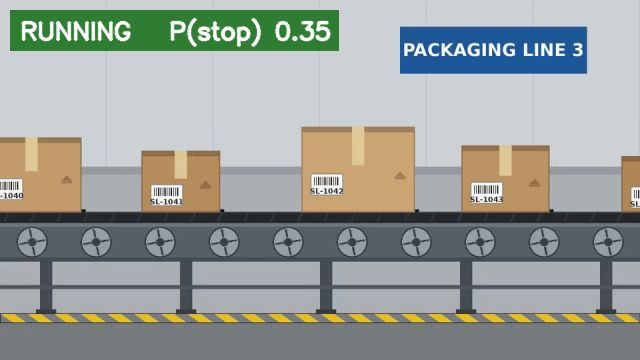

Demo ended. 'stop' detected 2 time(s) at: [4.2, 36.4] seconds


In [33]:
import cv2
from IPython.display import Image

VIDEO_PATH = Path("/Users/Tanmay/Downloads/conveyor_belt.mp4")
STOP_THRESHOLD = 0.6
SMOOTH_WINDOWS = 2
HOP_SECONDS = 0.25
PAUSE_SECONDS = 5.0
DEMO_SECONDS = 120
DISPLAY_WIDTH = 640
DISPLAY_FPS = 15

video = cv2.VideoCapture(str(VIDEO_PATH))
assert video.isOpened(), f"Could not open {VIDEO_PATH}"
VIDEO_FPS = video.get(cv2.CAP_PROP_FPS) or 30.0
print(f"Video: {VIDEO_PATH.name} | {int(video.get(cv2.CAP_PROP_FRAME_WIDTH))} x "
      f"{int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))} | {VIDEO_FPS:.0f} fps")


def read_video_frame():
    ok, frame = video.read()
    if not ok:
        video.set(cv2.CAP_PROP_POS_FRAMES, 0)
        ok, frame = video.read()
    return frame


def frame_to_jpeg(frame, stopped, p_stop):
    h, w = frame.shape[:2]
    img = cv2.resize(frame, (DISPLAY_WIDTH, int(h * DISPLAY_WIDTH / w)), interpolation=cv2.INTER_AREA)
    color = (40, 40, 200) if stopped else (50, 125, 46)
    label = "BELT STOPPED" if stopped else f"RUNNING   P(stop) {p_stop:.2f}"
    cv2.rectangle(img, (10, 10), (10 + 14 * len(label) + 20, 50), color, -1)
    cv2.putText(img, label, (20, 39), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
    if stopped:
        cv2.rectangle(img, (0, 0), (img.shape[1] - 1, img.shape[0] - 1), color, 8)
    return cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 80])[1].tobytes()


audio_q = queue.Queue()


def mic_callback(indata, frames, time_info, status):
    audio_q.put(indata[:, 0].copy())


window = np.zeros(MIC_RATE, dtype=np.float32)
recent = deque(maxlen=SMOOTH_WINDOWS)
paused_until = 0.0
stop_count = 0
events = []
p_smooth = 0.0
current_frame = read_video_frame()
video_view = display(Image(data=frame_to_jpeg(current_frame, False, 0.0)), display_id=True)

try:
    with sd.InputStream(device=MIC_DEVICE, channels=1, samplerate=MIC_RATE, dtype="float32",
                        blocksize=int(MIC_RATE * HOP_SECONDS), callback=mic_callback):
        start_time = time.time()
        video_clock = start_time
        while time.time() - start_time < DEMO_SECONDS:
            loop_start = time.time()

            if not audio_q.empty():
                chunks = []
                while not audio_q.empty():
                    chunks.append(audio_q.get())
                new_audio = np.concatenate(chunks)[-MIC_RATE:]
                window = np.concatenate([window[len(new_audio):], new_audio])
                recent.append(stop_probability(to_model_rate(window)))
                p_smooth = float(np.mean(recent))
                now = time.time()
                if p_smooth >= STOP_THRESHOLD and now >= paused_until:
                    paused_until = now + PAUSE_SECONDS
                    stop_count += 1
                    recent.clear()
                    events.append(round(now - start_time, 1))

            now = time.time()
            stopped = now < paused_until
            if stopped:
                video_clock = now
            else:
                frames_due = int((now - video_clock) * VIDEO_FPS)
                if frames_due > 0:
                    for _ in range(frames_due - 1):
                        video.grab()
                    current_frame = read_video_frame()
                    video_clock += frames_due / VIDEO_FPS

            video_view.update(Image(data=frame_to_jpeg(current_frame, stopped, p_smooth)))
            time.sleep(max(0.0, 1.0 / DISPLAY_FPS - (time.time() - loop_start)))
except KeyboardInterrupt:
    pass

video.release()
print(f"Demo ended. 'stop' detected {stop_count} time(s) at: {events} seconds")